<a href="https://colab.research.google.com/github/iamnoob96/Akshar_Sinha/blob/main/Phase_1_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cell 1: Import Libraries and Load Dataset

In [1]:
import pandas as pd  # Import pandas library for data manipulation and analysis.
import numpy as np  # Import numpy library for numerical mathematical operations.
import matplotlib.pyplot as plt  # Import matplotlib for custom data visualizations.
import seaborn as sns  # Import seaborn for statistical data visualizations.

sns.set(style="whitegrid")  # Set seaborn default visualization style to whitegrid.
plt.rcParams['figure.figsize'] = (10, 6)  # Set default figure dimensions for matplotlib plots.

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/happiness.csv"  # Define URL pointing to raw csv dataset source.
df = pd.read_csv(url)  # Load csv dataset directly into pandas DataFrame.

print("Shape of dataset:", df.shape)  # Print row and column dimensions of loaded dataset.
display(df.head())  # Display first five rows of the loaded DataFrame.

Shape of dataset: (17137, 34)


,rownames,year,workstat,prestige,divorce,widowed,educ,reg16,babies,preteen,...,occattend,regattend,y94,y96,y98,y00,y02,y04,y06,unem10
0,1,1994,keeping house,46.0,NaN,iap,12.0,middle atlantic,2.0,3.0,...,1.0,0.0,1,0,0,0,0,0,0,1.0
1,2,1994,working fulltime,22.0,no,iap,12.0,foreign,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0
2,3,1994,working fulltime,29.0,no,iap,12.0,foreign,0.0,0.0,...,0.0,1.0,1,0,0,0,0,0,0,NaN
3,4,1994,working fulltime,42.0,yes,iap,8.0,foreign,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,1.0
4,5,1994,working parttime,36.0,NaN,NaN,13.0,middle atlantic,0.0,1.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0


# Cell 2: Basic Statistical Analysis

In [2]:
print("Dataset Info:")  # Print header label for dataset structural details.
df.info()  # Display concise summary of columns, data types, and non-null counts.

print("\nStatistical Summary (numeric + categorical):")  # Print header label for summary statistics.
display(df.describe(include='all').T)  # Transpose and display summary statistics for all data types.

print("\nUnique values per column:")  # Print header label for column unique value counts.
display(df.nunique().sort_values(ascending=False))  # Display unique values count per column sorted from highest to lowest.

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17137 entries, 0 to 17136
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     17137 non-null  int64  
 1   year         17137 non-null  int64  
 2   workstat     17134 non-null  object 
 3   prestige     16283 non-null  float64
 4   divorce      9754 non-null   object 
 5   widowed      11096 non-null  object 
 6   educ         17093 non-null  float64
 7   reg16        17137 non-null  object 
 8   babies       17036 non-null  float64
 9   preteen      17036 non-null  float64
 10  teens        17049 non-null  float64
 11  income       15045 non-null  object 
 12  region       17137 non-null  object 
 13  attend       16864 non-null  object 
 14  happy        17137 non-null  object 
 15  owngun       11297 non-null  object 
 16  tvhours      11794 non-null  float64
 17  vhappy       17137 non-null  int64  
 18  mothfath16   17132 non-null  flo

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,17137.0,NaN,NaN,NaN,8569.0,4947.170117,1.0,4285.0,8569.0,12853.0,17137.0
year,17137.0,NaN,NaN,NaN,1999.47412,4.143358,1994.0,1996.0,1998.0,2004.0,2006.0
workstat,17134,8,working fulltime,9214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prestige,16283.0,NaN,NaN,NaN,43.877541,13.873965,17.0,33.0,43.0,51.0,86.0
divorce,9754,2,no,7421,NaN,NaN,NaN,NaN,NaN,NaN,NaN
widowed,11096,2,iap,10718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
educ,17093.0,NaN,NaN,NaN,13.319078,2.986785,0.0,12.0,13.0,16.0,20.0
reg16,17137,10,e. nor. central,3148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
babies,17036.0,NaN,NaN,NaN,0.207091,0.540542,0.0,0.0,0.0,0.0,6.0
preteen,17036.0,NaN,NaN,NaN,0.255753,0.621533,0.0,0.0,0.0,0.0,6.0



Unique values per column:


,0
rownames,17137
prestige,59
tvhours,22
educ,21
income,12
reg16,10
region,9
attend,9
workstat,8
year,7


# Cell 3: Handling Missing Data

,Missing Count,Missing %
gwbush04,15207,88.737819
gwbush00,13701,79.949816
divorce,7383,43.082220
widowed,6041,35.251211
owngun,5840,34.078310
unem10,5796,33.821556
tvhours,5343,31.178153
income,2092,12.207504
prestige,854,4.983369
attend,273,1.593044


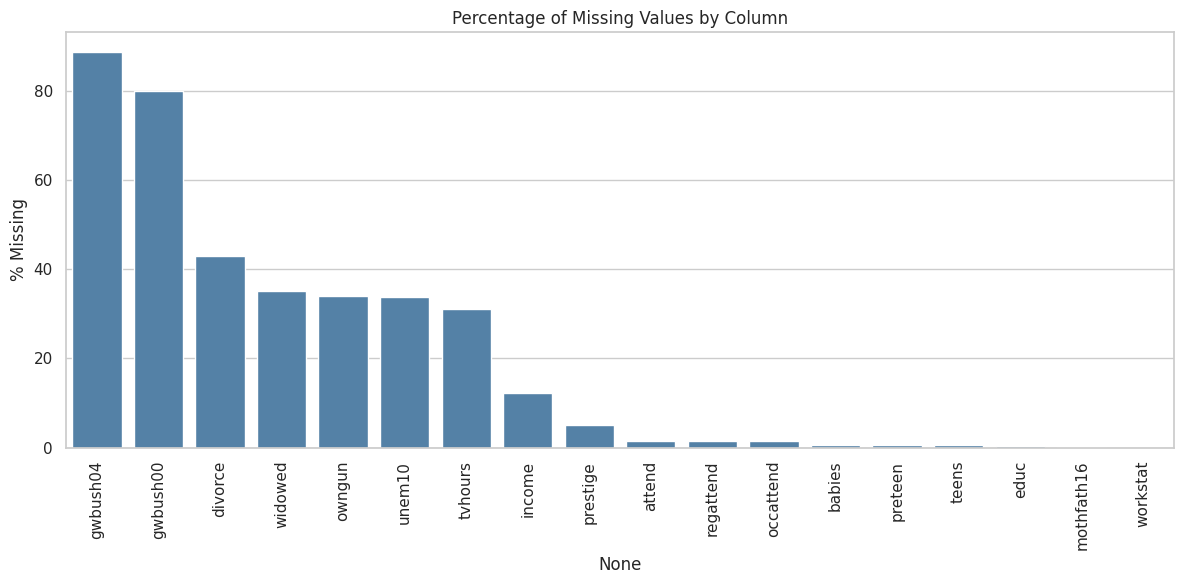

Dropped columns (>40% missing): ['gwbush04', 'gwbush00', 'divorce']

Remaining missing values after imputation: 0


In [3]:
missing = df.isnull().sum()  # Count null values present in each column of DataFrame.
missing_pct = (missing / len(df)) * 100  # Compute percentage of missing values per column.
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})  # Construct new DataFrame to show missing metrics.
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)  # Filter and sort missing columns.
display(missing_df)  # Render missing data summary table in output.

plt.figure(figsize=(12, 6))  # Initialize figure canvas for displaying missing percentages.
sns.barplot(x=missing_df.index, y=missing_df['Missing %'], color='steelblue')  # Draw vertical bar chart for missing metrics.
plt.xticks(rotation=90)  # Rotate x-axis label ticks by 90 degrees for better legibility.
plt.title("Percentage of Missing Values by Column")  # Set title of missing percentages plot.
plt.ylabel("% Missing")  # Set y-axis label for percentage scale.
plt.tight_layout()  # Adjust margins automatically to prevent label clipping.
plt.show()  # Display plot in notebook interface.

cols_to_drop = missing_df[missing_df['Missing %'] > 40].index.tolist()  # Identify columns with missing rates exceeding 40%.
df.drop(columns=cols_to_drop, inplace=True)  # Remove identified columns from the DataFrame permanently.
print("Dropped columns (>40% missing):", cols_to_drop)  # Print list of columns removed.

for col in df.columns:  # Iterate over remaining columns in DataFrame.
    if df[col].isnull().sum() > 0:  # Check if current column contains missing values.
        if df[col].dtype in ['float64', 'int64']:  # Check if data type is numerical.
            df[col] = df[col].fillna(df[col].median())  # Fill numeric missing elements with column median.
        else:  # For categorical columns.
            df[col] = df[col].fillna(df[col].mode()[0])  # Fill non-numeric missing elements with column mode.

print("\nRemaining missing values after imputation:", df.isnull().sum().sum())  # Print grand total of remaining missing entries.

# Cell 4: Data Cleaning

In [4]:
before = df.shape[0]  # Record number of rows prior to duplicate removal.
df.drop_duplicates(inplace=True)  # Drop duplicate records in-place from DataFrame.
print(f"Removed {before - df.shape[0]} duplicate rows")  # Report quantity of duplicate rows removed.

cat_cols = df.select_dtypes(include='object').columns  # Identify categorical object columns.
for col in cat_cols:  # Iterate through object columns.
    df[col] = df[col].astype(str).str.strip().str.lower()  # Standardize text elements to lowercase and remove spaces.

df.replace('iap', np.nan, inplace=True)  # Substitute 'iap' values with real missing NaN values.
for col in df.columns:  # Loop over DataFrame features.
    if df[col].isnull().sum() > 0:  # Check for remaining nulls.
        if df[col].dtype in ['float64', 'int64']:  # Check if numerical.
            df[col] = df[col].fillna(df[col].median())  # Impute numerical nulls with median.
        else:  # Else categorical.
            df[col] = df[col].fillna(df[col].mode()[0])  # Impute categorical nulls with mode.

print("Data cleaning complete. Shape:", df.shape)  # Report post-cleaning DataFrame size.
display(df.head())  # Preview cleaned dataset.

Removed 0 duplicate rows
Data cleaning complete. Shape: (17137, 31)


,rownames,year,workstat,prestige,widowed,educ,reg16,babies,preteen,teens,...,occattend,regattend,y94,y96,y98,y00,y02,y04,y06,unem10
0,1,1994,keeping house,46.0,yes,12.0,middle atlantic,2.0,3.0,0.0,...,1.0,0.0,1,0,0,0,0,0,0,1.0
1,2,1994,working fulltime,22.0,yes,12.0,foreign,0.0,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0
2,3,1994,working fulltime,29.0,yes,12.0,foreign,0.0,0.0,0.0,...,0.0,1.0,1,0,0,0,0,0,0,0.0
3,4,1994,working fulltime,42.0,yes,8.0,foreign,0.0,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,1.0
4,5,1994,working parttime,36.0,yes,13.0,middle atlantic,0.0,1.0,1.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0


# Cell 5: Data Transformation

In [5]:
income_order = ['lt $1000', '$1000 to 2999', '$3000 to 3999', '$4000 to 4999', '$5000 to 5999', '$6000 to 6999', '$7000 to 7999', '$8000 to 9999', '$10000 - 14999', '$15000 - 19999', '$20000 - 24999', '$25000 or more']  # Set categorical sort order for income values.
income_map = {val: i for i, val in enumerate(income_order)}  # Map string levels to ordinal numerical indices.
df['income_ordinal'] = df['income'].map(income_map)  # Produce new numeric ordinal income column in DataFrame.
df['income_ordinal'] = df['income_ordinal'].fillna(df['income_ordinal'].median())  # Impute missing ordinal levels using median.

happy_order = ['not too happy', 'pretty happy', 'very happy']  # Define logical level hierarchy for happiness.
df['happy'] = pd.Categorical(df['happy'], categories=happy_order, ordered=True)  # Convert column into ordered categorical type.
df['happy_score'] = df['happy'].cat.codes  # Extract integer encodings for happiness rankings.

df['total_children'] = df['babies'] + df['preteen'] + df['teens']  # Accumulate values of child demographic columns.

print("New columns added: income_ordinal, happy_score, total_children")  # Announce features generated.
display(df[['income', 'income_ordinal', 'happy', 'happy_score', 'total_children']].head())  # Verify transformations.

New columns added: income_ordinal, happy_score, total_children


,income,income_ordinal,happy,happy_score,total_children
0,$10000 - 14999,8,pretty happy,1,5.0
1,$25000 or more,11,very happy,2,0.0
2,$15000 - 19999,9,pretty happy,1,0.0
3,$15000 - 19999,9,not too happy,0,0.0
4,$10000 - 14999,8,not too happy,0,2.0


# Cell 6: Univariate Analysis

/tmp/ipykernel_941/1593562907.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='happy', data=df, order=happy_order, palette='viridis')  # Plot categorical counts of happiness levels.


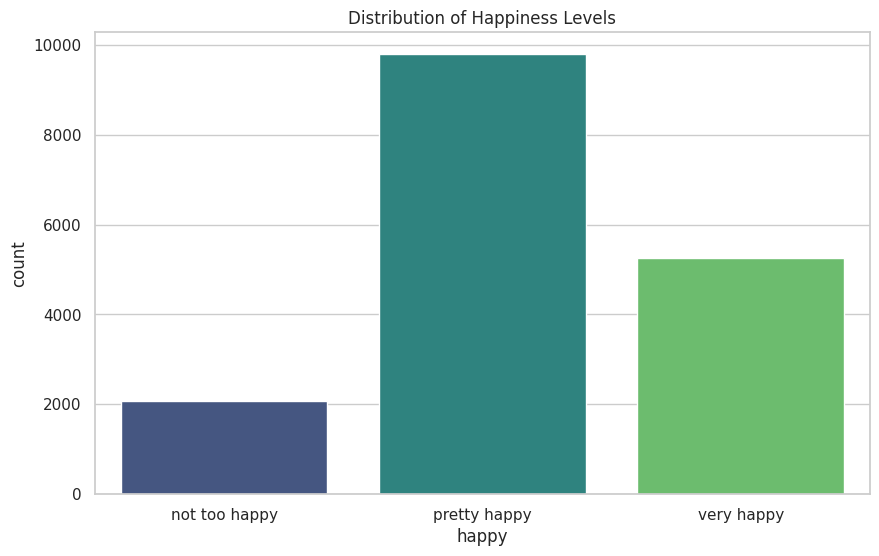

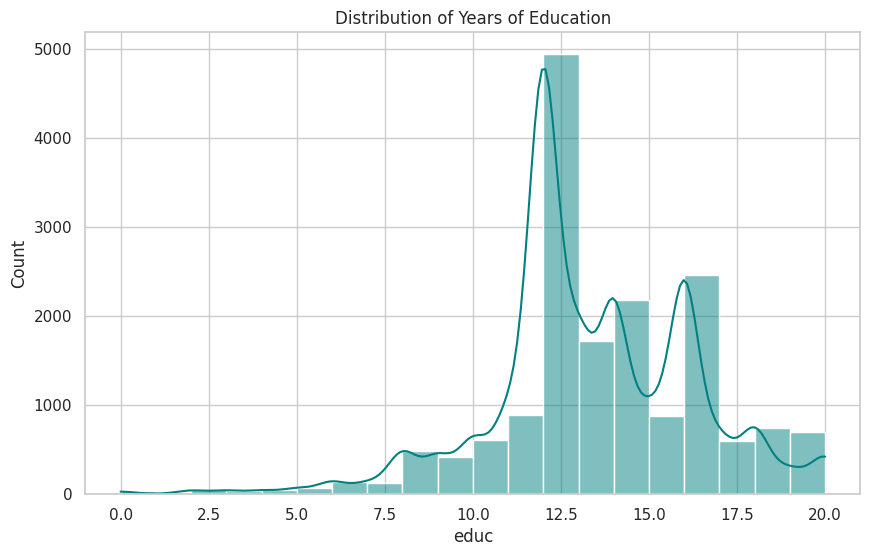

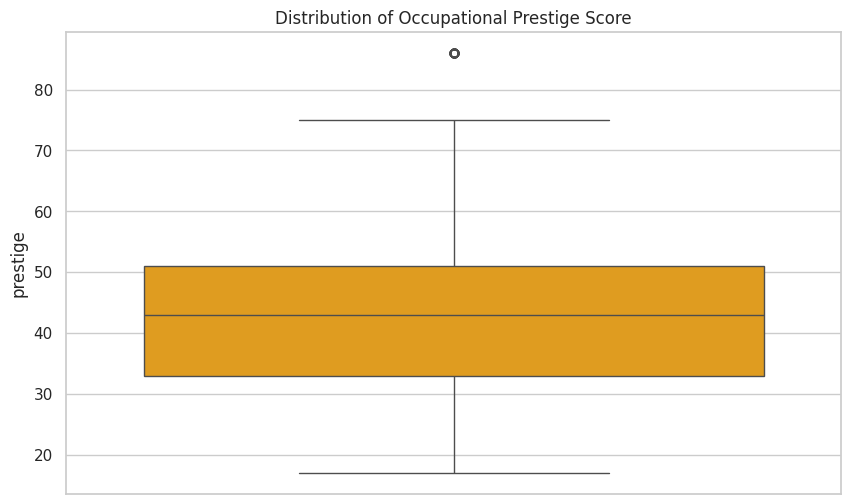

In [6]:
plt.figure()  # Instantiate plot window for count distribution.
sns.countplot(x='happy', data=df, order=happy_order, palette='viridis')  # Plot categorical counts of happiness levels.
plt.title("Distribution of Happiness Levels")  # Add descriptive title.
plt.show()  # Draw happiness count plot.

plt.figure()  # Instantiate visualization window.
sns.histplot(df['educ'], bins=20, kde=True, color='teal')  # Graph histogram of education attribute.
plt.title("Distribution of Years of Education")  # Apply descriptive title.
plt.show()  # Display education histogram.

plt.figure()  # Create visual canvas.
sns.boxplot(y=df['prestige'], color='orange')  # Construct boxplot depicting occupational prestige spread.
plt.title("Distribution of Occupational Prestige Score")  # Title prestige plot.
plt.show()  # Render prestige boxplot.

# Cell 7: Bivariate Analysis

/tmp/ipykernel_941/231044244.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='happy', y='income_ordinal', data=df, order=happy_order, palette='coolwarm')  # Plot income distributions per happiness category.


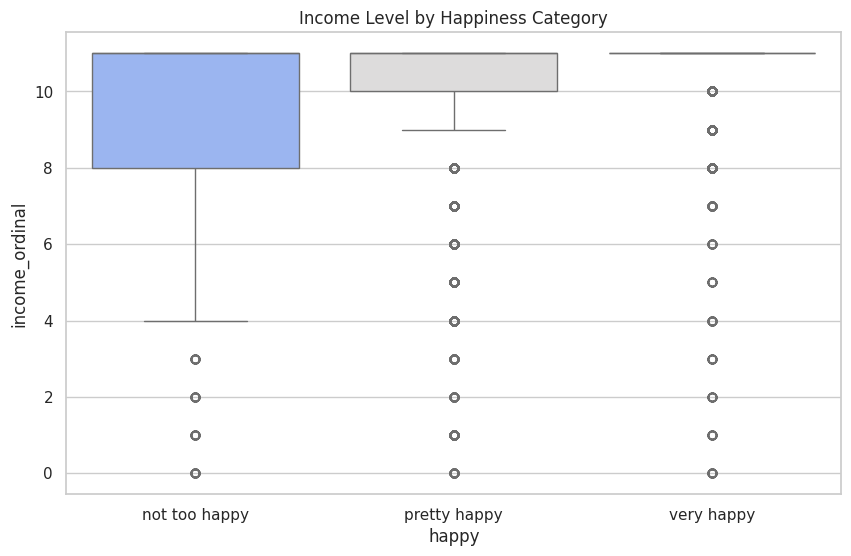

/tmp/ipykernel_941/231044244.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='happy', y='educ', data=df, order=happy_order, palette='mako')  # Plot education distributions per happiness category.


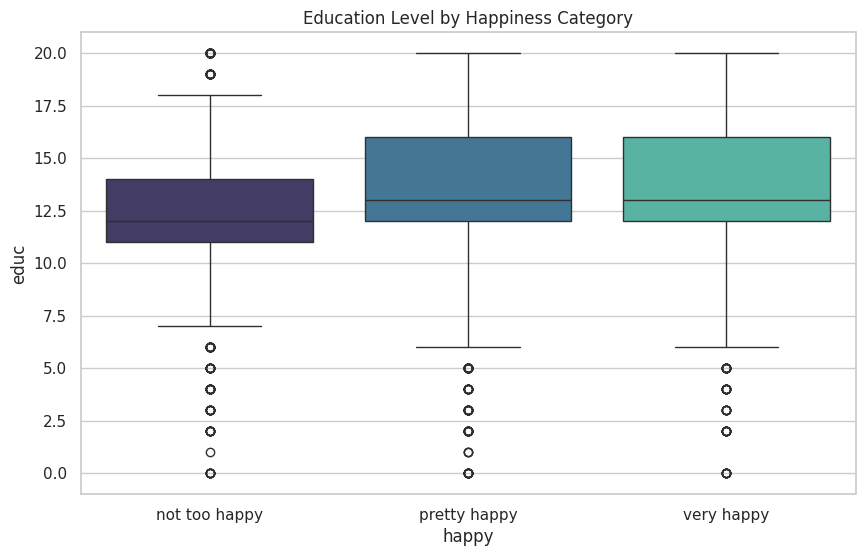

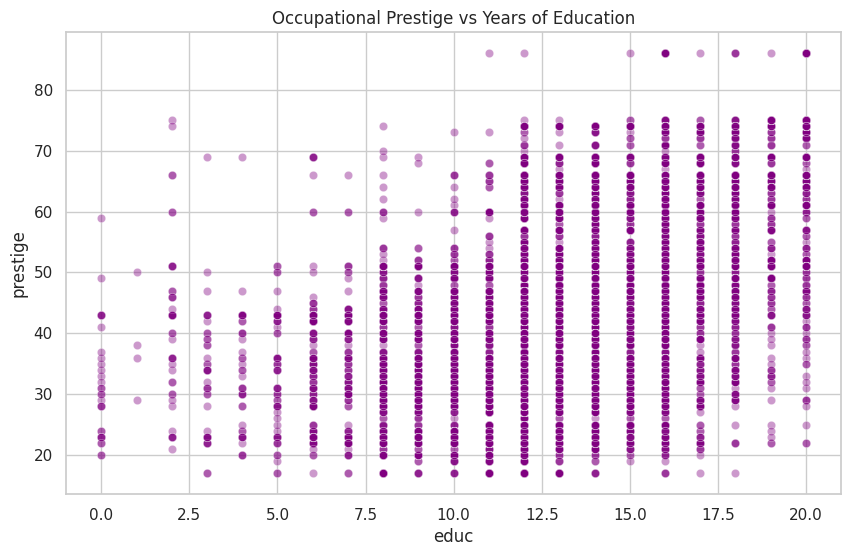

In [7]:
plt.figure()  # Open figure canvas.
sns.boxplot(x='happy', y='income_ordinal', data=df, order=happy_order, palette='coolwarm')  # Plot income distributions per happiness category.
plt.title("Income Level by Happiness Category")  # Add title.
plt.show()  # Output boxplot.

plt.figure()  # Start canvas.
sns.boxplot(x='happy', y='educ', data=df, order=happy_order, palette='mako')  # Plot education distributions per happiness category.
plt.title("Education Level by Happiness Category")  # Apply title.
plt.show()  # Output boxplot.

plt.figure()  # Start plot layout.
sns.scatterplot(x='educ', y='prestige', data=df, alpha=0.4, color='purple')  # Correlate education and prestige in a scatter layout.
plt.title("Occupational Prestige vs Years of Education")  # Add scatter title.
plt.show()  # Output plot.

# Cell 8: Multivariate Analysis

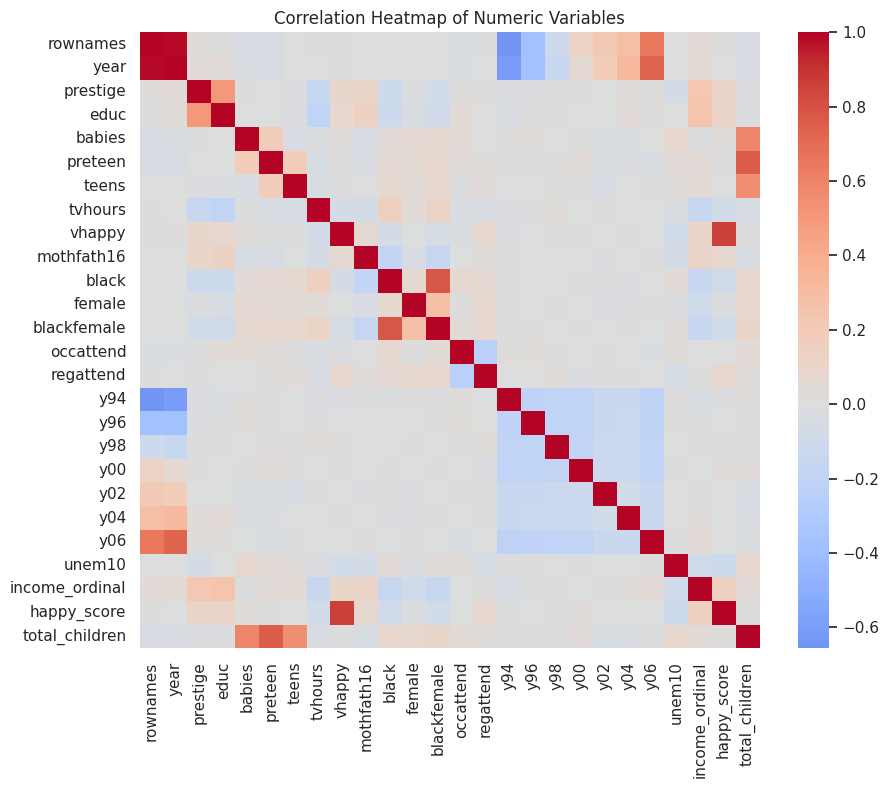

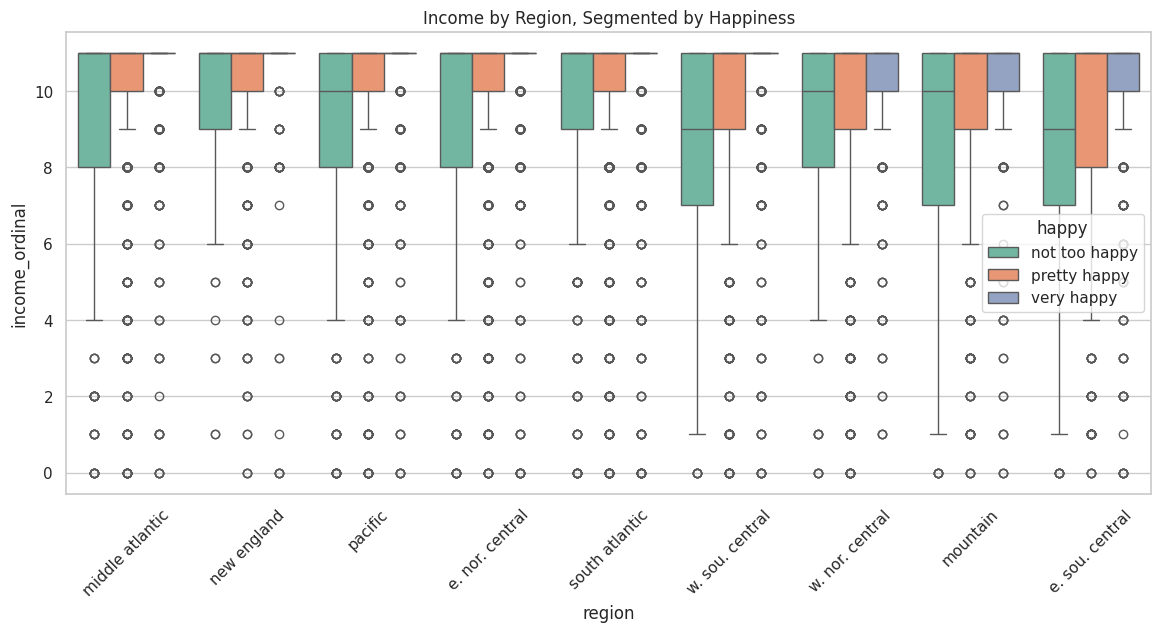

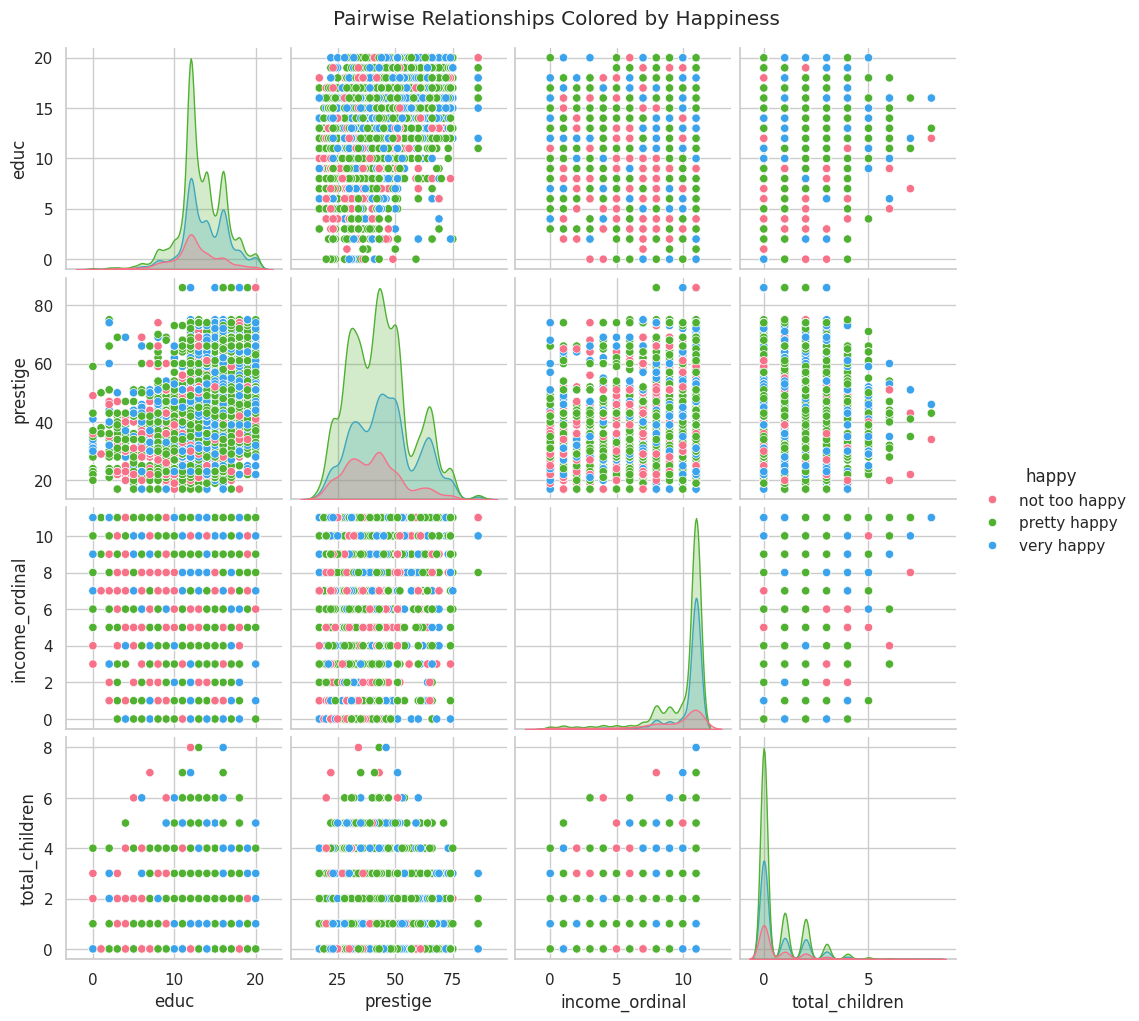

In [8]:
plt.figure(figsize=(10, 8))  # Establish correlation plot canvas dimensions.
numeric_cols = df.select_dtypes(include=[np.number]).columns  # Filter dataset columns to only numerical ones.
corr = df[numeric_cols].corr()  # Extract Pearson correlation coefficients matrix.
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)  # Render coefficients on a centered color heatmap.
plt.title("Correlation Heatmap of Numeric Variables")  # Set heatmap title.
plt.show()  # Render heatmap.

plt.figure(figsize=(14, 6))  # Initialize region comparative visual canvas.
sns.boxplot(x='region', y='income_ordinal', hue='happy', data=df, palette='Set2')  # Boxplot comparing regional income split by happiness.
plt.title("Income by Region, Segmented by Happiness")  # Set boxplot title.
plt.xticks(rotation=45)  # Rotate labels.
plt.show()  # Output boxplot.

key_vars = ['educ', 'prestige', 'income_ordinal', 'total_children', 'happy']  # Enlist core analytics features.
sns.pairplot(df[key_vars], hue='happy', palette='husl', diag_kind='kde')  # Generate pairgrid matrix plots.
plt.suptitle("Pairwise Relationships Colored by Happiness", y=1.02)  # Add over-arching title.
plt.show()  # Output pairwise plot grid.

# Phase II - Statistical Analysis and Clustering

## 1D Statistical Analysis

In [9]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()  # Collate raw numeric feature list.
cat_cols = df.select_dtypes(include='object').columns.tolist()  # Collate raw text/categorical object list.

exclude_cols = ['rownames', 'y94', 'y96', 'y98', 'y00', 'y02', 'y04', 'y06', 'black', 'female', 'blackfemale']  # Define target indicators to skip.

num_cols = [col for col in num_cols if col not in exclude_cols]  # Drop target indicators from analytics feature list.

print("Numerical Columns:")  # Label printed output block.
print(num_cols)  # Print clean list of continuous attributes.

print("\nCategorical Columns:")  # Label categorical block.
print(cat_cols)  # Print clean list of object/discrete columns.

Numerical Columns:
['year', 'prestige', 'educ', 'babies', 'preteen', 'teens', 'tvhours', 'vhappy', 'mothfath16', 'occattend', 'regattend', 'unem10', 'income_ordinal', 'happy_score', 'total_children']

Categorical Columns:
['workstat', 'widowed', 'reg16', 'income', 'region', 'attend', 'owngun']


### Numerical Statistical Measures

In [10]:
selected_num = ['prestige', 'educ', 'babies', 'preteen', 'teens', 'tvhours']  # Nominate numeric columns for profiling.
selected_num = [col for col in selected_num if col in df.columns]  # Confirm nominated features are inside actual columns.

stats_1d = pd.DataFrame({  # Compile a statistics overview dataframe.
    'Count': df[selected_num].count(),  # Populate rows with quantity counts.
    'Mean': df[selected_num].mean(),  # Populate rows with calculated averages.
    'Median': df[selected_num].median(),  # Populate rows with center/50th-percentile indicators.
    'Mode': df[selected_num].mode().iloc[0],  # Extract and place primary modal entries.
    'Minimum': df[selected_num].min(),  # Compute lowest boundary indices.
    'Maximum': df[selected_num].max(),  # Compute peak boundary values.
    'Range': df[selected_num].max() - df[selected_num].min(),  # Calculate span intervals.
    'Variance': df[selected_num].var(),  # Compute statistical dispersion levels.
    'Standard Deviation': df[selected_num].std(),  # Compute standard deviation indicators.
    'Q1': df[selected_num].quantile(0.25),  # Locate 25th percentile marks.
    'Q3': df[selected_num].quantile(0.75),  # Locate 75th percentile marks.
    'IQR': df[selected_num].quantile(0.75) - df[selected_num].quantile(0.25),  # Derive interquartile range values.
    'Skewness': df[selected_num].skew(),  # Evaluate distribution asymmetry ratios.
    'Kurtosis': df[selected_num].kurt()  # Assess peak tail distributions.
})  # Close DataFrame compilation block.

display(stats_1d)  # Display 1D statistical summary table.

,Count,Mean,Median,Mode,Minimum,Maximum,Range,Variance,Standard Deviation,Q1,Q3,IQR,Skewness,Kurtosis
prestige,17137,43.833810,43.0,51.0,17.0,86.0,69.0,182.930479,13.525179,33.0,51.0,18.0,0.401339,-0.367514
educ,17137,13.318259,13.0,12.0,0.0,20.0,20.0,8.898239,2.982992,12.0,16.0,4.0,-0.359070,1.342281
babies,17137,0.205870,0.0,0.0,0.0,6.0,6.0,0.290715,0.539180,0.0,0.0,0.0,2.971922,9.762498
preteen,17137,0.254245,0.0,0.0,0.0,6.0,6.0,0.384410,0.620008,0.0,0.0,0.0,2.826627,9.173960
teens,17137,0.180428,0.0,0.0,0.0,7.0,7.0,0.242654,0.492599,0.0,0.0,0.0,3.176989,12.340826
tvhours,17137,2.622163,2.0,2.0,0.0,24.0,24.0,3.903391,1.975700,2.0,3.0,1.0,3.346928,19.225030


### Frequency Distribution

In [11]:
freq = df['happy'].value_counts()  # Tabulate occurrences for every categorical level of happiness.
relative_freq = df['happy'].value_counts(normalize=True) * 100  # Compute proportional percentages.

frequency_table = pd.DataFrame({  # Build a comparative distribution lookup table.
    'Frequency': freq,  # Link raw value counts.
    'Percentage': relative_freq  # Link computed percentage distribution.
})  # Close table generation.

display(frequency_table)  # Print resulting happiness frequency analysis.

,Frequency,Percentage
happy,,
pretty happy,9791,57.133687
very happy,5260,30.693820
not too happy,2086,12.172492


### Histogram

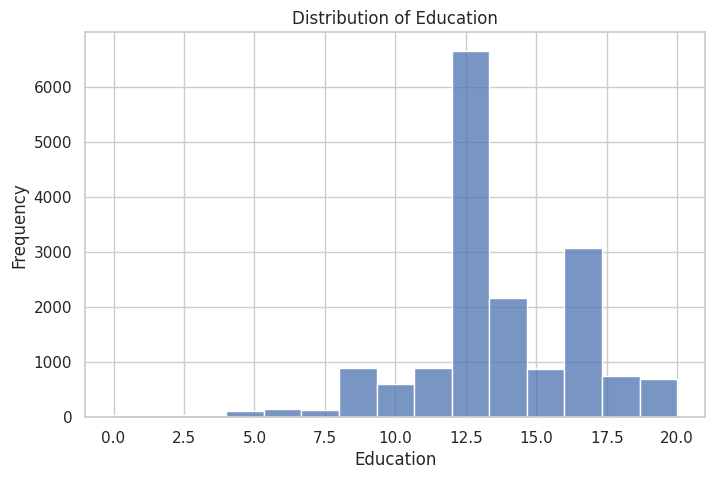

In [12]:
plt.figure(figsize=(8, 5))  # Create canvas frame.
sns.histplot(df['educ'].dropna(), bins=15, kde=False)  # Plot raw distribution of non-null academic years.
plt.title('Distribution of Education')  # Add chart title.
plt.xlabel('Education')  # Add label.
plt.ylabel('Frequency')  # Label vertical axis.
plt.show()  # Display distribution histogram.

### Density Plot

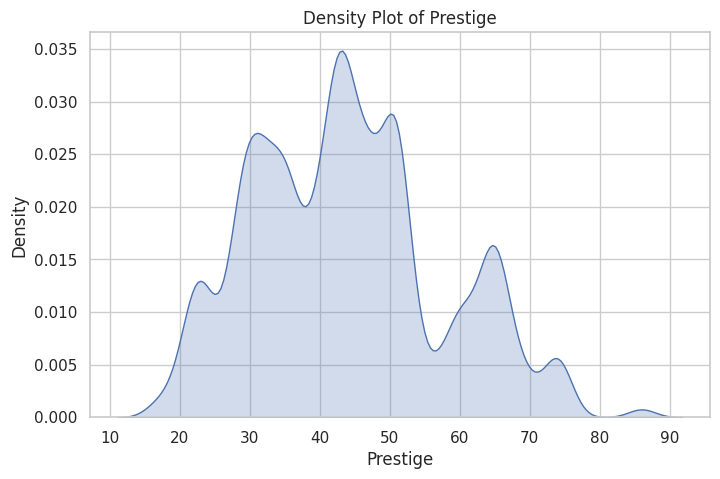

In [13]:
plt.figure(figsize=(8, 5))  # Build coordinate frame.
sns.kdeplot(data=df, x='prestige', fill=True)  # Draw a kernel density estimate over occupational status.
plt.title('Density Plot of Prestige')  # Set plot header title.
plt.xlabel('Prestige')  # Define label.
plt.ylabel('Density')  # Define vertical density index scale.
plt.show()  # Output plot.

### Box Plot

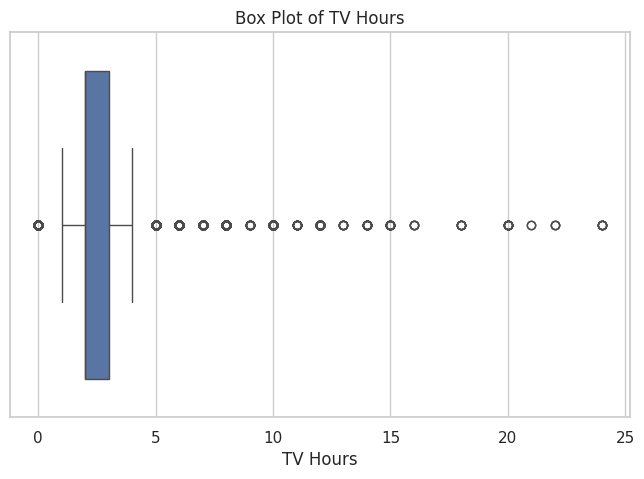

In [14]:
plt.figure(figsize=(8, 5))  # Set plot dimensions.
sns.boxplot(data=df, x='tvhours')  # Plot a box and whisker diagram representing television hours.
plt.title('Box Plot of TV Hours')  # Title visualization.
plt.xlabel('TV Hours')  # Label visual axis.
plt.show()  # Show boxplot.

### Categorical Distribution

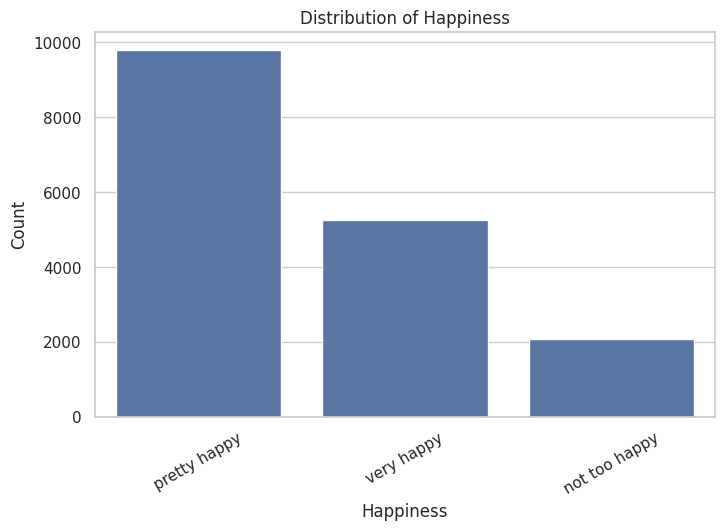

In [15]:
plt.figure(figsize=(8, 5))  # Open layout canvas.
sns.countplot(data=df, x='happy', order=df['happy'].value_counts().index)  # Plot a ranked frequency count of categorical happiness levels.
plt.title('Distribution of Happiness')  # Add title.
plt.xlabel('Happiness')  # Assign descriptive label.
plt.ylabel('Count')  # Define scale units.
plt.xticks(rotation=30)  # Tilt label ticks for legibility.
plt.show()  # Output distribution chart.

## 2D Statistical Analysis

### Numerical vs Numerical

In [16]:
pair_data = df[['educ', 'prestige']].dropna()  # Subset features and clean any null rows.

covariance = pair_data['educ'].cov(pair_data['prestige'])  # Calculate statistical covariance.
pearson = pair_data['educ'].corr(pair_data['prestige'], method='pearson')  # Compute Pearson correlation.
spearman = pair_data['educ'].corr(pair_data['prestige'], method='spearman')  # Compute Spearman rank coefficient.

print("Covariance:", covariance)  # Display covariance.
print("Pearson Correlation:", pearson)  # Display linear correlation.
print("Spearman Correlation:", spearman)  # Display rank relationship factor.

Covariance: 20.434488847278818
Pearson Correlation: 0.5064874853662135
Spearman Correlation: 0.5066500976761565


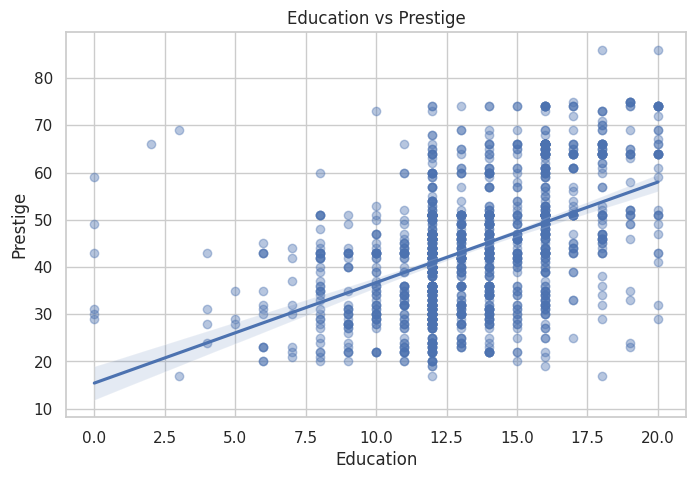

In [17]:
plot_data = pair_data.sample(n=min(1500, len(pair_data)), random_state=42)  # Extract sample to dodge dense points overlay.

plt.figure(figsize=(8, 5))  # Define plot bounds.
sns.regplot(data=plot_data, x='educ', y='prestige', scatter_kws={'alpha': 0.4})  # Plot scatter points and overlay a regression line.
plt.title('Education vs Prestige')  # Assign plot title.
plt.xlabel('Education')  # Set horizontal description.
plt.ylabel('Prestige')  # Set vertical description.
plt.show()  # Draw regression plot.

### Numerical vs Categorical

In [18]:
group_stats = df.groupby('happy', observed=True)['prestige'].agg(['count', 'mean', 'median', 'std'])  # Aggregate prestige stats grouped by happiness.
display(group_stats)  # Render aggregated stats table.

,count,mean,median,std
happy,,,,
not too happy,2086,40.788111,41.0,12.548961
pretty happy,9791,43.466755,43.0,13.442325
very happy,5260,45.724905,45.0,13.774754


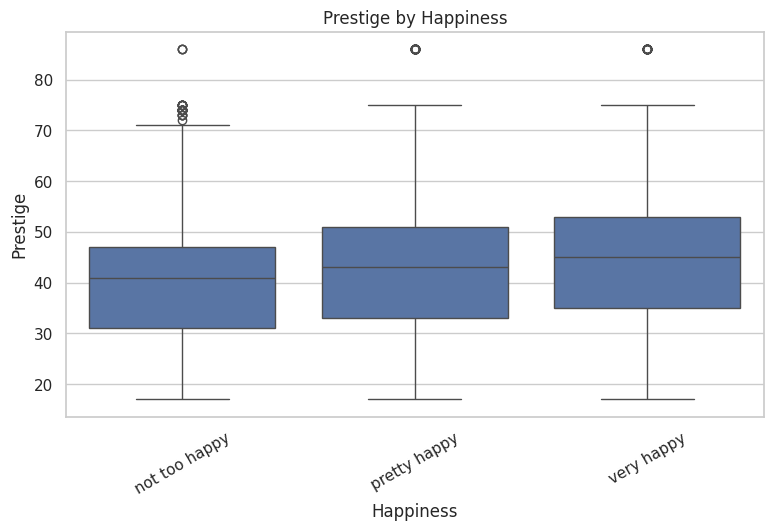

In [19]:
plt.figure(figsize=(9, 5))  # Start canvas framework.
sns.boxplot(data=df, x='happy', y='prestige')  # Generate boxplot comparing prestige spread over happiness ratings.
plt.title('Prestige by Happiness')  # Label diagram.
plt.xlabel('Happiness')  # Set label text.
plt.ylabel('Prestige')  # Define numerical axis label.
plt.xticks(rotation=30)  # Tilt category labels.
plt.show()  # Present plot.

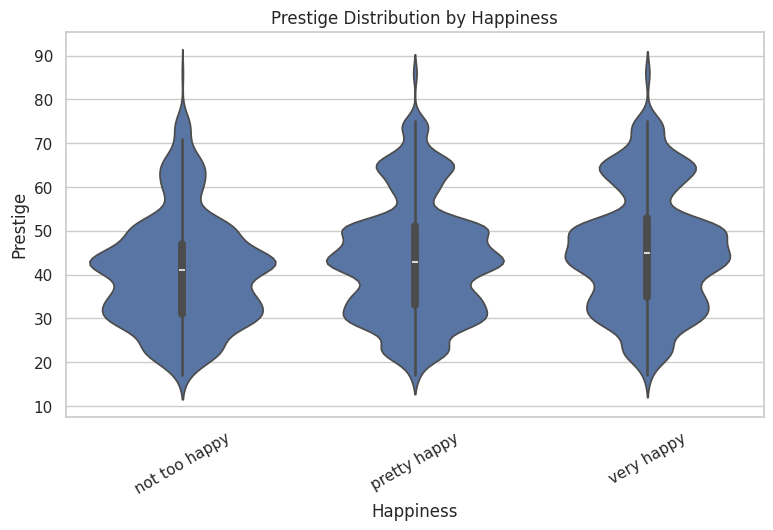

In [20]:
plt.figure(figsize=(9, 5))  # Initiate visual canvas.
sns.violinplot(data=df, x='happy', y='prestige')  # Generate violinplot showing prestige distributions across happiness states.
plt.title('Prestige Distribution by Happiness')  # Title display.
plt.xlabel('Happiness')  # Add label.
plt.ylabel('Prestige')  # Add label.
plt.xticks(rotation=30)  # Tilt label labels.
plt.show()  # Display plot.

### Categorical vs Categorical

In [21]:
from scipy.stats import chi2_contingency  # Import scipy test module for categorical analysis.

contingency = pd.crosstab(df['happy'], df['workstat'])  # Build actual frequency crosstabulation array.
display(contingency)  # Render contingency array matrix.

percentage_table = pd.crosstab(df['happy'], df['workstat'], normalize='index') * 100  # Compute percentage contingency matrix normalized by row indexes.
display(percentage_table)  # Render normalized percentage matrix.

workstat,keeping house,other,retired,school,temp not working,"unempl, laid off",working fulltime,working parttime
happy,,,,,,,,
not too happy,275,121,321,71,56,143,877,222
pretty happy,1011,200,1268,302,186,272,5475,1077
very happy,626,75,870,148,93,70,2865,513


workstat,keeping house,other,retired,school,temp not working,"unempl, laid off",working fulltime,working parttime
happy,,,,,,,,
not too happy,13.183126,5.800575,15.388303,3.403643,2.684564,6.855225,42.042186,10.642378
pretty happy,10.325809,2.042692,12.950669,3.084465,1.899704,2.778061,55.918701,10.999898
very happy,11.901141,1.425856,16.539924,2.813688,1.768061,1.330798,54.467681,9.752852


In [22]:
chi2, p, dof, expected = chi2_contingency(contingency)  # Run chi-square independence test.

print("Chi-Square Statistic:", chi2)  # Print test statistic output.
print("P-Value:", p)  # Print resulting significance p-value.
print("Degrees of Freedom:", dof)  # Display calculated freedom degrees.

expected_df = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)  # Construct theoretical expectation limits dataframe.
display(expected_df)  # Display theoretical table values.

Chi-Square Statistic: 416.8554941526411
P-Value: 3.548156941471278e-80
Degrees of Freedom: 14


workstat,keeping house,other,retired,school,temp not working,"unempl, laid off",working fulltime,working parttime
happy,,,,,,,,
not too happy,232.738052,48.203069,299.321585,63.418685,40.777849,59.036588,1121.938612,220.565560
pretty happy,1092.396102,226.249402,1404.917372,297.666511,191.397853,277.098384,5266.011962,1035.262415
very happy,586.865846,121.547529,754.761043,159.914804,102.824298,148.865029,2829.049425,556.172025


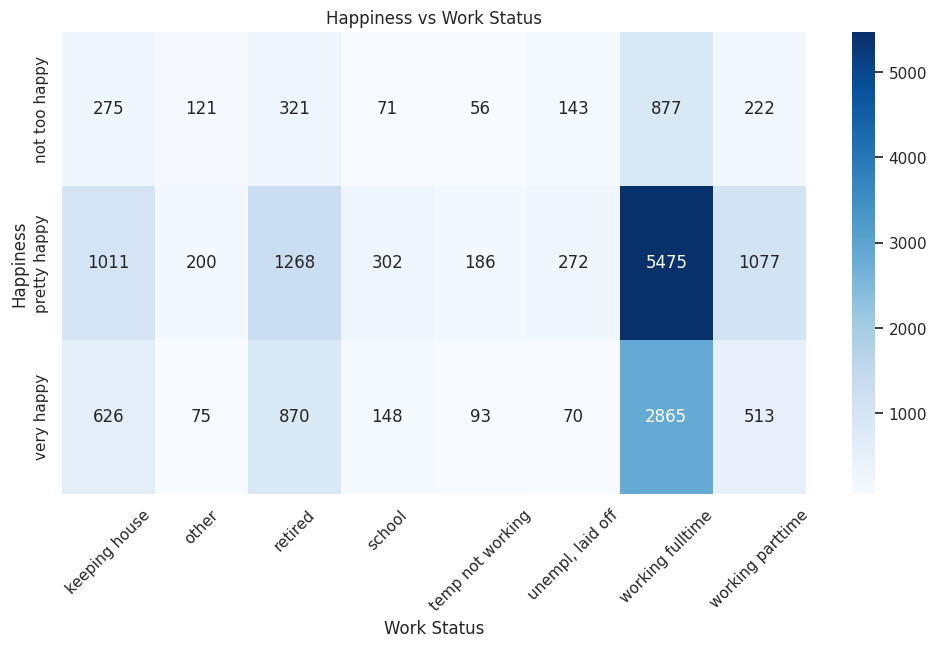

In [23]:
plt.figure(figsize=(12, 6))  # Establish canvas bounds.
sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues')  # Render actual numbers using a blue shaded heatmap matrix.
plt.title('Happiness vs Work Status')  # Set plot title.
plt.xlabel('Work Status')  # Add coordinate label.
plt.ylabel('Happiness')  # Add vertical axis title.
plt.xticks(rotation=45)  # Tilt category labels.
plt.show()  # Present plot.

## 3D Statistical Analysis

### 3D Scatter Plot

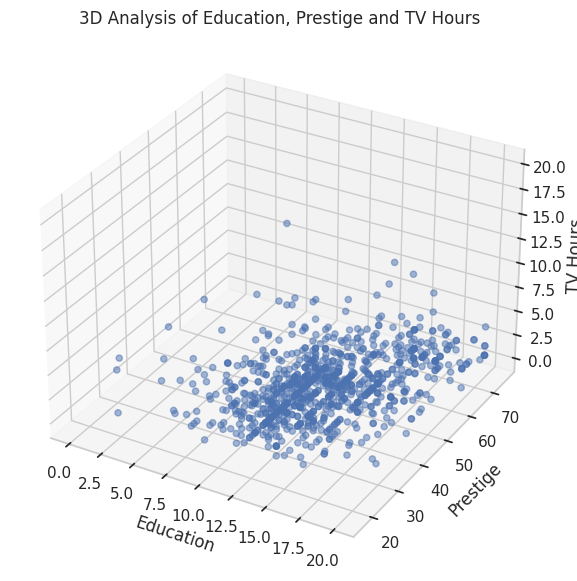

In [24]:
from mpl_toolkits.mplot3d import Axes3D  # Import module required to project coordinates onto a 3D coordinate space.

three_d = df[['educ', 'prestige', 'tvhours']].dropna()  # Subset continuous elements and discard incomplete rows.
three_d = three_d.sample(n=min(1000, len(three_d)), random_state=42)  # Extract sample rows to simplify spatial graphics density.

fig = plt.figure(figsize=(10, 7))  # Establish canvas space.
ax = fig.add_subplot(111, projection='3d')  # Construct 3D projection axes inside plot layout.

ax.scatter(  # Build scatter points.
    three_d['educ'],  # Set education values on x-axis.
    three_d['prestige'],  # Set prestige values on y-axis.
    three_d['tvhours'],  # Set TV hours values on z-axis.
    alpha=0.5  # Configure point transparency.
)  # End plot creation block.

ax.set_xlabel('Education')  # Set x-coordinate description.
ax.set_ylabel('Prestige')  # Set y-coordinate description.
ax.set_zlabel('TV Hours')  # Set z-coordinate description.
ax.set_title('3D Analysis of Education, Prestige and TV Hours')  # Apply title.

plt.show()  # Display 3D projection.

### Three Variable Scatter Plot

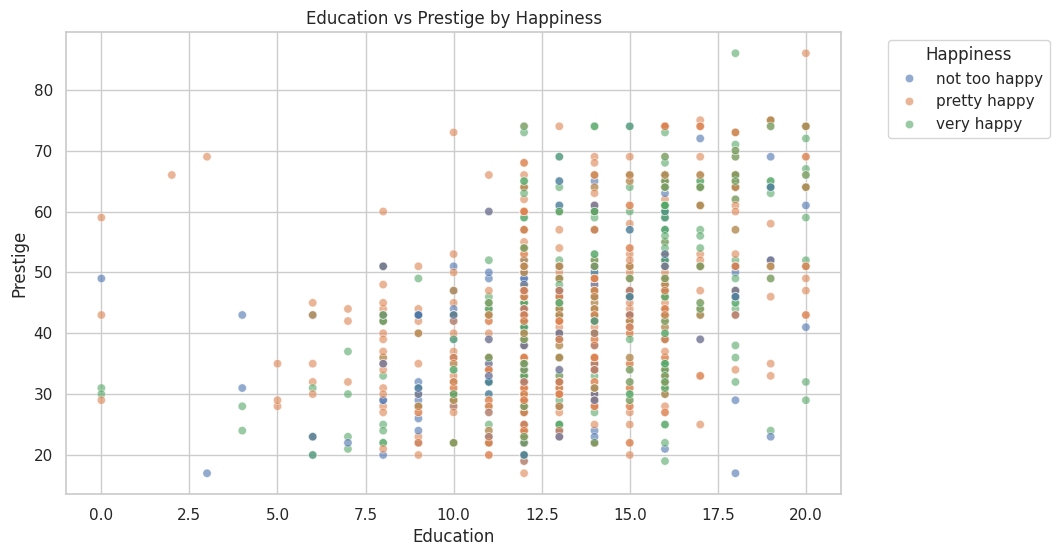

In [25]:
multi_data = df[['educ', 'prestige', 'happy']].dropna()  # Subset analytical elements and clear missing lines.
multi_data = multi_data.sample(n=min(1500, len(multi_data)), random_state=42)  # Sample data to avoid excessive marker overlaps.

plt.figure(figsize=(10, 6))  # Instantiate canvas.
sns.scatterplot(  # Initialize point coordinates.
    data=multi_data,  # Direct data lookup source.
    x='educ',  # Set education scale on x-axis.
    y='prestige',  # Set prestige scale on y-axis.
    hue='happy',  # Color-code markers based on happiness categories.
    alpha=0.6  # Set plotting opacity.
)  # End scatter call.
plt.title('Education vs Prestige by Happiness')  # Title plot.
plt.xlabel('Education')  # Assign coordinate label.
plt.ylabel('Prestige')  # Assign coordinate label.
plt.legend(title='Happiness', bbox_to_anchor=(1.05, 1))  # Align legend sidebar outside the plot area.
plt.show()  # Present multi-dimensional plot.

### Bubble Plot

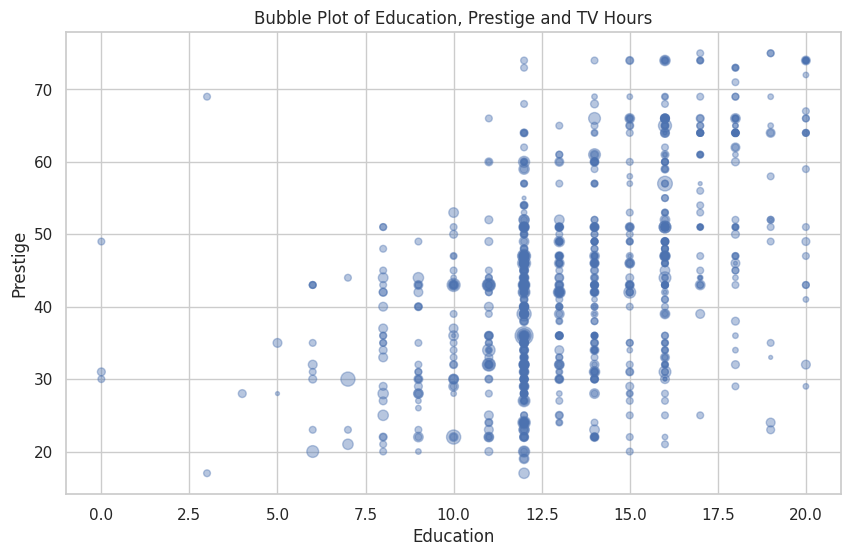

In [26]:
bubble_data = df[['educ', 'prestige', 'tvhours']].dropna()  # Select necessary columns and clean invalid rows.
bubble_data = bubble_data.sample(n=min(1000, len(bubble_data)), random_state=42)  # Draw sample records to optimize marker distribution.

sizes = bubble_data['tvhours'].clip(lower=0) + 1  # Standardize size factors ensuring non-negative scales.

plt.figure(figsize=(10, 6))  # Establish canvas.
plt.scatter(  # Construct plot elements manually.
    bubble_data['educ'],  # Point education as x-coordinates.
    bubble_data['prestige'],  # Point prestige as y-coordinates.
    s=sizes * 8,  # Map visual bubble markers size using TV hours factor.
    alpha=0.4  # Configure transparency.
)  # End bubble call.
plt.title('Bubble Plot of Education, Prestige and TV Hours')  # Name visualization.
plt.xlabel('Education')  # Set axis header.
plt.ylabel('Prestige')  # Set axis header.
plt.show()  # Draw bubble chart.

### Grouped Three Variable Analysis

In [27]:
grouped_analysis = df.groupby(['happy', 'workstat'], observed=True)['prestige'].agg(['count', 'mean', 'median']).round(2)  # Compute aggregate metrics grouping by categorical levels.
display(grouped_analysis)  # Display result table.

count   mean  median
happy         workstat                              
not too happy keeping house       275  38.85    42.0
              other               121  38.67    39.0
              retired             321  41.21    42.0
              school               71  41.61    43.0
              temp not working     56  43.88    42.5
              unempl, laid off    143  39.15    36.0
              working fulltime    877  41.87    41.0
              working parttime    222  39.45    36.0
pretty happy  keeping house      1011  40.13    43.0
              other               200  40.66    41.5
              retired            1268  44.00    43.0
              school              302  40.70    43.0
              temp not working    186  43.39    42.0
              unempl, laid off    272  39.49    38.5
              working fulltime   5475  45.06    44.0
              working parttime   1077  40.18    38.0
very happy    keeping house       626  42.72    43.0
              other                75  42.36    43.0
              retired             870  45.96    46.0
              school              148  41.70    43.0
              temp not working     93  47.59    45.0
              unempl, laid off     70  40.67    39.0
              working fulltime   2865  47.43    47.0
              working parttime    513  41.47    39.0

### Pair Plot

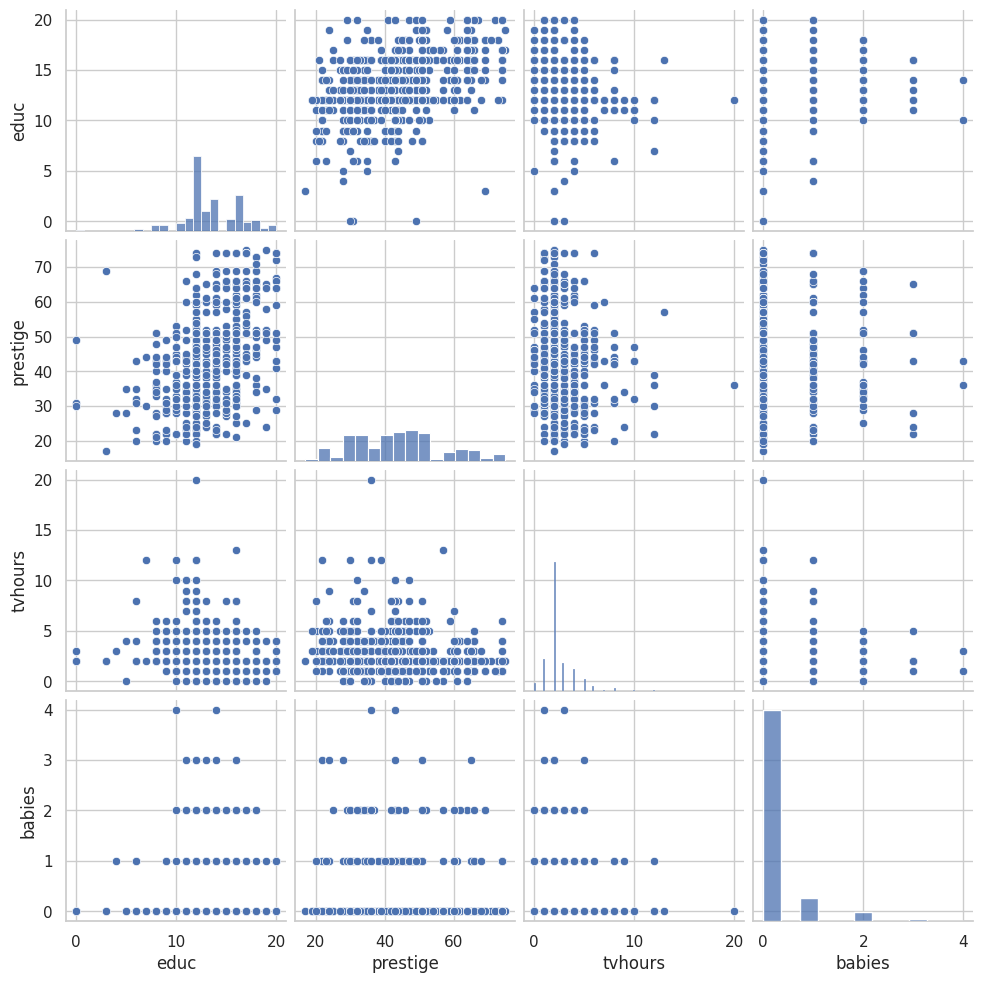

In [28]:
pairplot_data = df[['educ', 'prestige', 'tvhours', 'babies']].dropna()  # Select features and discard incomplete entries.
pairplot_data = pairplot_data.sample(n=min(800, len(pairplot_data)), random_state=42)  # Extract sample to keep pair-grid rendering fast.

sns.pairplot(pairplot_data)  # Plot pairwise relationships matrix across all selected numerical columns.
plt.show()  # Display plot grid.

### Correlation Heatmap

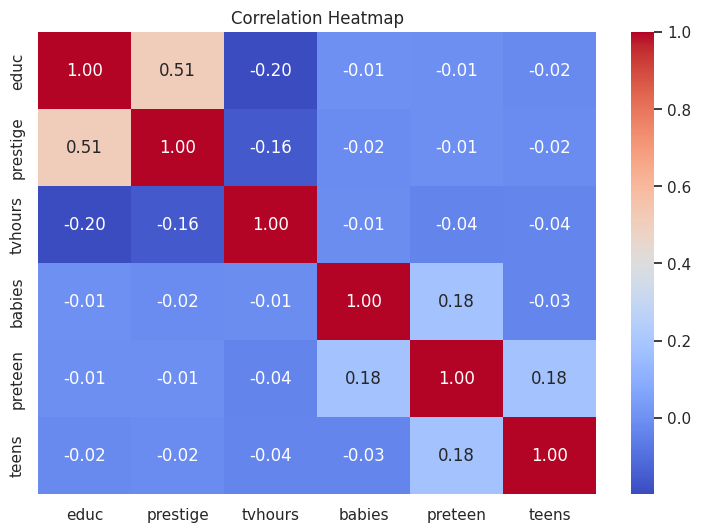

In [29]:
corr_features = ['educ', 'prestige', 'tvhours', 'babies', 'preteen', 'teens']  # Nominate numeric features for correlation analysis.
corr_features = [col for col in corr_features if col in df.columns]  # Filter columns to only those actually present in the DataFrame.

corr_matrix = df[corr_features].corr()  # Extract the computed Pearson correlation matrix.

plt.figure(figsize=(9, 6))  # Start canvas framework.
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')  # Render correlation index values on a heatmap chart.
plt.title('Correlation Heatmap')  # Set title.
plt.show()  # Display heatmap.

# K-Means Clustering

### Data Preparation

In [30]:
from sklearn.preprocessing import StandardScaler  # Import StandardScaler to standardize numerical coordinates.
from sklearn.cluster import KMeans  # Import KMeans to fit a cluster algorithm.
from sklearn.metrics import silhouette_score  # Import silhouette_score to evaluate cluster partitions.

cluster_features = ['prestige', 'educ', 'tvhours', 'babies']  # Define target features chosen for segment clustering.
cluster_features = [col for col in cluster_features if col in df.columns]  # Keep columns that exist in DataFrame.

cluster_data = df[cluster_features].dropna().copy()  # Subset non-empty records into copy array.

scaler = StandardScaler()  # Initialize scaling object.
X_scaled = scaler.fit_transform(cluster_data)  # Scale analytical records to standard normal boundaries.

print("Features:", cluster_features)  # Confirm features list.
print("Number of Observations:", len(cluster_data))  # Show overall size of formatted cluster array.

Features: ['prestige', 'educ', 'tvhours', 'babies']
Number of Observations: 17137


### Elbow Method

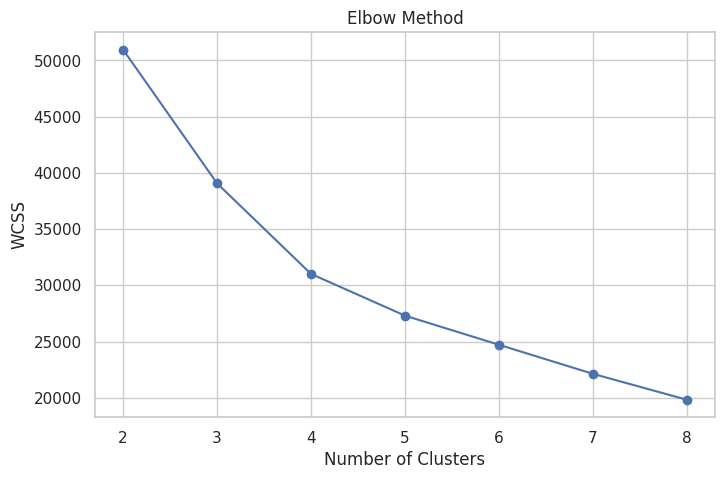

In [31]:
inertias = []  # Initialize empty list to accumulate within-cluster sum-of-squares.
k_values = range(2, 9)  # Set the test span for cluster limits.

for k in k_values:  # Iterate over proposed K counts.
    model = KMeans(n_clusters=k, random_state=42, n_init=10)  # Configure KMeans estimator model.
    model.fit(X_scaled)  # Fit estimator over standardized inputs.
    inertias.append(model.inertia_)  # Append computed within-cluster variance score.

plt.figure(figsize=(8, 5))  # Open layout canvas.
plt.plot(k_values, inertias, marker='o')  # Plot line displaying WCSS decline across K boundaries.
plt.title('Elbow Method')  # Title plot.
plt.xlabel('Number of Clusters')  # Label coordinate.
plt.ylabel('WCSS')  # Label metric index.
plt.xticks(list(k_values))  # Set ticks matching tested values.
plt.show()  # Draw elbow chart.

### Silhouette Analysis

In [32]:
silhouette_scores = []  # Initialize list to record average score elements.

for k in k_values:  # Iterate through different cluster quantities.
    model = KMeans(n_clusters=k, random_state=42, n_init=10)  # Build KMeans estimator instance.
    labels = model.fit_predict(X_scaled)  # Run segmentation modeling on standardized values.
    score = silhouette_score(X_scaled, labels)  # Compute silhouette score for current partition layout.
    silhouette_scores.append(score)  # Store metric score.

silhouette_table = pd.DataFrame({  # Compile evaluation lookup table.
    'K': list(k_values),  # Set testing counts column.
    'Silhouette Score': silhouette_scores  # Set computed scores column.
})  # Close DataFrame compilation.

display(silhouette_table)  # Print silhouette table summary.

,K,Silhouette Score
0,2,0.271138
1,3,0.318318
2,4,0.341404
3,5,0.257273
4,6,0.263172
5,7,0.275468
6,8,0.280899


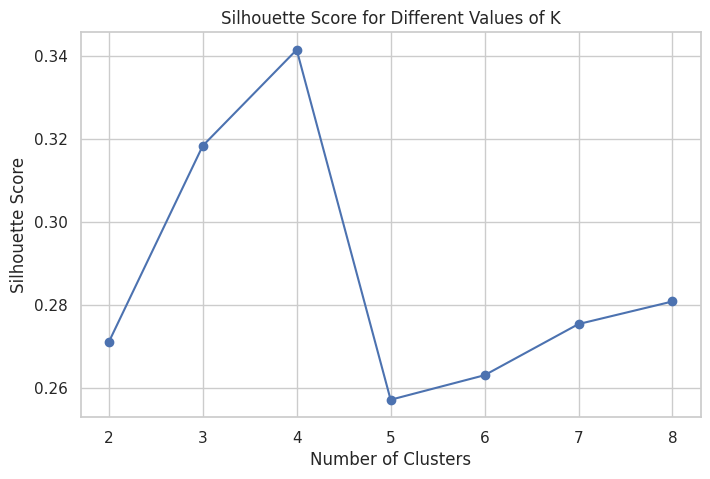

In [33]:
plt.figure(figsize=(8, 5))  # Build coordinate canvas frame.
plt.plot(k_values, silhouette_scores, marker='o')  # Render line demonstrating silhouette level trends over K boundaries.
plt.title('Silhouette Score for Different Values of K')  # Add descriptive title.
plt.xlabel('Number of Clusters')  # Label coordinate.
plt.ylabel('Silhouette Score')  # Label vertical metrics axes scale.
plt.xticks(list(k_values))  # Pin ticks at each integer evaluation boundary.
plt.show()  # Output score line plot.

### Final K-Means Model

In [34]:
best_k = list(k_values)[np.argmax(silhouette_scores)]  # Automatically find optimal K count with the maximum silhouette score.

kext_estimator = KMeans(n_clusters=best_k, random_state=42, n_init=10)  # Construct final KMeans model with best K count.
kmeans_labels = kext_estimator.fit_predict(X_scaled)  # Generate partition indexes across all scaled observations.

kmeans_data = cluster_data.copy()  # Create distinct copy of analytical variables.
kmeans_data['Cluster'] = kmeans_labels  # Save partition indices directly into custom copy array.

print("Selected Number of Clusters:", best_k)  # Report picked optimal K model segment size.
print("\nCluster Counts:")  # Set section label for value distribution prints.
display(kmeans_data['Cluster'].value_counts().sort_index())  # Display size split across different output clusters.

Selected Number of Clusters: 4

Cluster Counts:


,count
Cluster,
0,8540
1,5314
2,2248
3,1035


### Cluster Centres

In [35]:
scaled_centers = pd.DataFrame(  # Assemble standardized centers table.
    kext_estimator.cluster_centers_,  # Extract coordinate matrices.
    columns=cluster_features  # Match column names to selected feature headers.
)  # End standardized DataFrame creation.

original_centers = pd.DataFrame(  # Compile real-scale center indices dataframe.
    scaler.inverse_transform(kext_estimator.cluster_centers_),  # Map standardized bounds back to original scales.
    columns=cluster_features  # Match column names to feature headers.
)  # End real-scale DataFrame creation.

print("Standardized Cluster Centres:")  # Print section title.
display(scaled_centers)  # Display scaled centroid location values.

print("Cluster Centres in Original Scale:")  # Print section title.
display(original_centers)  # Display physical coordinates of partition centroids.

Standardized Cluster Centres:


,prestige,educ,tvhours,babies
0,-0.532332,-0.486015,-0.113000,-0.380519
1,1.015093,0.928069,-0.314917,-0.296697
2,-0.207751,-0.112212,-0.156853,2.219565
3,-0.468347,-0.602596,2.903018,-0.163208


Cluster Centres in Original Scale:


,prestige,educ,tvhours,babies
0,36.634132,11.868524,2.398914,0.000708
1,57.562721,16.086601,2.000000,0.045902
2,41.024021,12.983541,2.312278,1.402580
3,37.499517,11.520773,8.357488,0.117874


### K-Means Cluster Visualization

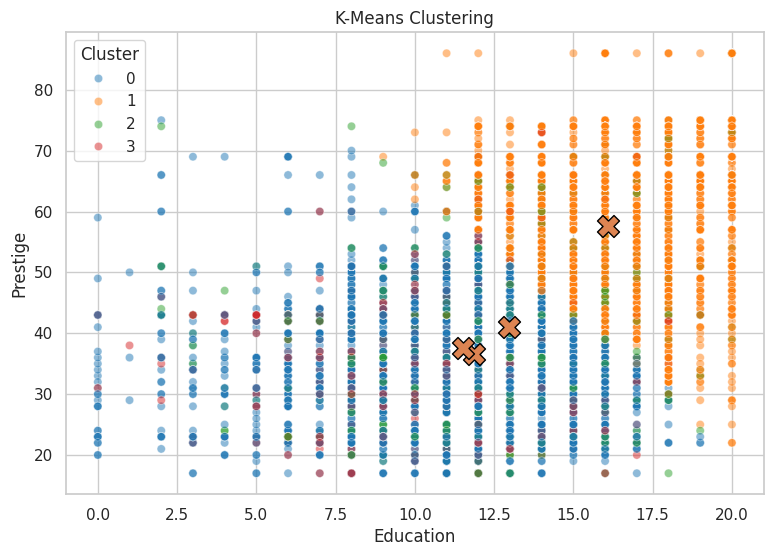

In [36]:
plt.figure(figsize=(9, 6))  # Establish coordinate dimensions.

sns.scatterplot(  # Draw individual points.
    data=kmeans_data,  # Set target source data.
    x='educ',  # Map education to x-axis.
    y='prestige',  # Map prestige to y-axis.
    hue='Cluster',  # Color-code based on final partition designations.
    palette='tab10',  # Choose discrete standard color scheme.
    alpha=0.5  # Configure point transparency.
)  # Close scatter configuration.

plt.scatter(  # Overlay centers markers manually.
    original_centers['educ'],  # Pin center point on x-axis.
    original_centers['prestige'],  # Pin center point on y-axis.
    s=250,  # Expand marker scale size for clear separation.
    marker='X',  # Style centroids as clear cross markers.
    edgecolor='black'  # Highlight marker with dark borders.
)  # End centroids overlay.

plt.title('K-Means Clustering')  # Apply title.
plt.xlabel('Education')  # Add label.
plt.ylabel('Prestige')  # Add label.
plt.show()  # Display visualization.

# Hierarchical Clustering

### Hierarchical Data Preparation

In [37]:
from scipy.cluster.hierarchy import linkage, dendrogram  # Import linkage algorithms and dendrogram plotting modules.
from sklearn.cluster import AgglomerativeClustering  # Import AgglomerativeClustering module.

hier_data = cluster_data.sample(  # Draw representative subset to prevent complex dendrogram structures.
    n=min(1000, len(cluster_data)),  # Set size limit bound of sampling.
    random_state=42  # Freeze randomized generation state for identical runs.
).copy()  # Save as clean DataFrame duplicate.

hier_scaled = scaler.transform(hier_data[cluster_features])  # Scale sampled data to correct standard boundaries.

print("Hierarchical Clustering Observations:", len(hier_data))  # Show overall length of subset observations array.

Hierarchical Clustering Observations: 1000


### Dendrogram

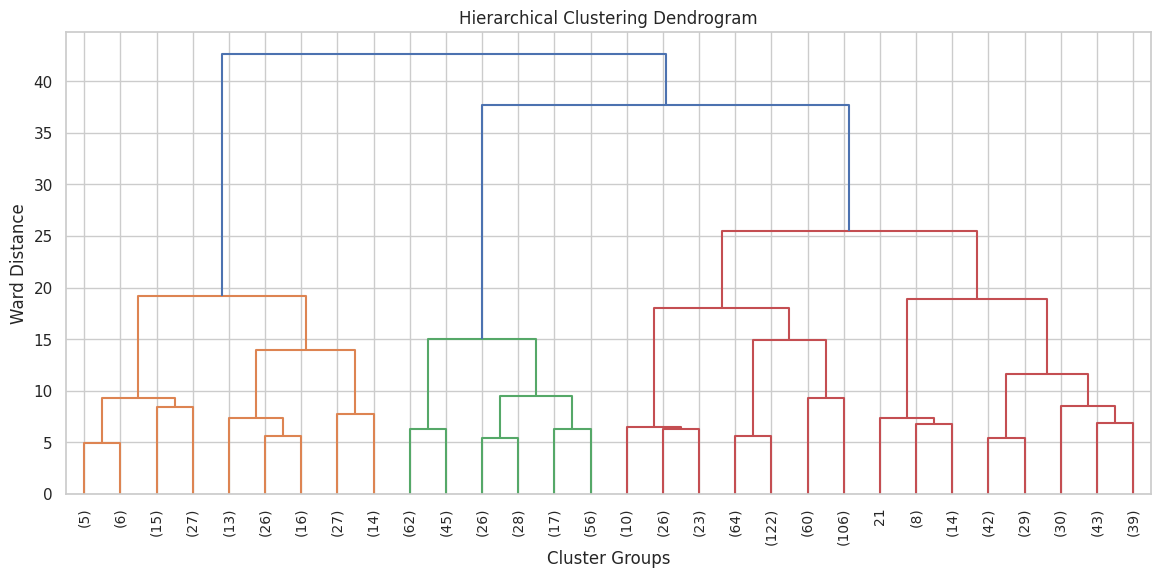

In [38]:
linkage_matrix = linkage(hier_scaled, method='ward')  # Run ward minimum variance linkage model on sample array.

plt.figure(figsize=(14, 6))  # Set plot size.
dendrogram(  # Render dendrogram.
    linkage_matrix,  # Pass link matrix calculated.
    truncate_mode='lastp',  # Keep only primary branches visible.
    p=30,  # Cap displayed nodes to 30 visible groups.
    leaf_rotation=90,  # Spin index label rotations for text layout safety.
    leaf_font_size=10  # Configure scale sizes.
)  # Close dendrogram call.
plt.title('Hierarchical Clustering Dendrogram')  # Apply title.
plt.xlabel('Cluster Groups')  # Set label.
plt.ylabel('Ward Distance')  # Define linkage separation metric scale.
plt.show()  # Display dendrogram tree chart.

### Agglomerative Clustering

In [39]:
hierarchical_model = AgglomerativeClustering(  # Configure agglomerative estimator.
    n_clusters=best_k,  # Fit model with optimal cluster size found prior.
    linkage='ward'  # Select ward linkage method.
)  # Close initialization.

hier_labels = hierarchical_model.fit_predict(hier_scaled)  # Run agglomerative partitioning across sampled items.

hier_result = hier_data.copy()  # Duplicate sample records DataFrame.
hier_result['Cluster'] = hier_labels  # Attach cluster labels to dataset copy.

print("Number of Clusters:", best_k)  # Report set cluster counts.
print("\nCluster Counts:")  # Print header.
display(hier_result['Cluster'].value_counts().sort_index())  # Display size split across different output clusters.

Number of Clusters: 4

Cluster Counts:


,count
Cluster,
0,149
1,206
2,234
3,411


### Hierarchical Cluster Visualization

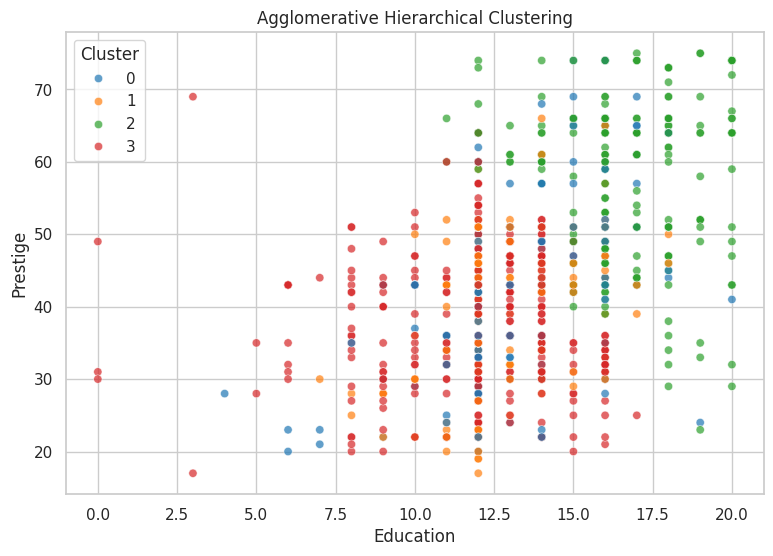

In [40]:
plt.figure(figsize=(9, 6))  # Establish canvas space.

sns.scatterplot(  # Plot individual scatter coordinates.
    data=hier_result,  # Direct coordinate data lookup source.
    x='educ',  # Map education to x-axis.
    y='prestige',  # Map prestige to y-axis.
    hue='Cluster',  # Color coordinates by Hierarchical cluster rankings.
    palette='tab10',  # Keep palette mapping matching prior plots.
    alpha=0.7  # Configure point transparency.
)  # End scatter call.

plt.title('Agglomerative Hierarchical Clustering')  # Apply plot title.
plt.xlabel('Education')  # Add label.
plt.ylabel('Prestige')  # Add label.
plt.show()  # Display plot.

### Hierarchical Silhouette Score

In [41]:
hierarchical_silhouette = silhouette_score(hier_scaled, hier_labels)  # Compute silhouette partitioning index on sample.
kmeans_silhouette = max(silhouette_scores)  # Retrieve best silhouette index computed during KMeans modeling.

print("K-Means Silhouette Score:", kmeans_silhouette)  # Report KMeans index.
print("Hierarchical Silhouette Score:", hierarchical_silhouette)  # Report sample Hierarchical silhouette index.

K-Means Silhouette Score: 0.34140439001725004
Hierarchical Silhouette Score: 0.25749496675862943


# Clustering Comparison

In [42]:
comparison = pd.DataFrame({  # Compile performance lookup dataframe.
    'Method': ['K-Means', 'Hierarchical'],  # Name methods evaluated.
    'Number of Clusters': [best_k, best_k],  # Document cluster partition counts used.
    'Silhouette Score': [kmeans_silhouette, hierarchical_silhouette]  # Link comparative metrics indexes.
})  # Close DataFrame compilation.

display(comparison)  # Print model comparison summary.

,Method,Number of Clusters,Silhouette Score
0,K-Means,4,0.341404
1,Hierarchical,4,0.257495


## Module 6: Principal Component Analysis (PCA)

### 6.1 Import Required Libraries

In [43]:
from sklearn.decomposition import PCA # Import PCA class for dimensionality reduction
from sklearn.preprocessing import StandardScaler # Import StandardScaler to standardize numerical features
import pandas as pd # Import pandas library for data frame manipulation
import numpy as np # Import numpy library for scientific numerical computations
import matplotlib.pyplot as plt # Import matplotlib pyplot module for plotting charts
import seaborn as sns # Import seaborn library for advanced statistical plots

### 6.2 Data Preparation

In [44]:
pca_cols = ['prestige', 'educ', 'tvhours', 'babies', 'preteen', 'teens'] # Define list of numeric columns for PCA
pca_data = df[pca_cols].copy() # Subset numerical columns from the existing DataFrame and copy
for col in pca_data.columns: # Loop through each selected column
    pca_data[col] = pca_data[col].fillna(pca_data[col].median()) # Fill missing values in columns with their median

display(pca_data.head()) # Display first 5 rows of the prepared numerical dataset
print("Prepared PCA dataset shape:", pca_data.shape) # Print shape of prepared numerical dataset

,prestige,educ,tvhours,babies,preteen,teens
0,46.0,12.0,2.0,2.0,3.0,0.0
1,22.0,12.0,3.0,0.0,0.0,0.0
2,29.0,12.0,1.0,0.0,0.0,0.0
3,42.0,8.0,3.0,0.0,0.0,0.0
4,36.0,13.0,2.0,0.0,1.0,1.0


Prepared PCA dataset shape: (17137, 6)


### 6.3 Feature Standardization

In [45]:
pca_scaler = StandardScaler() # Initialize the standard scaler to normalize mean to 0 and variance to 1
pca_scaled = pca_scaler.fit_transform(pca_data) # Fit and transform the prepared numerical data
pca_scaled_df = pd.DataFrame(pca_scaled, columns=pca_cols) # Convert the scaled array back to a pandas DataFrame

display(pca_scaled_df.head()) # Display first 5 rows of the standardized dataset
print("Standardized PCA dataset shape:", pca_scaled_df.shape) # Print shape of standardized dataset

,prestige,educ,tvhours,babies,preteen,teens
0,0.160164,-0.441938,-0.314917,3.327614,4.428707,-0.366289
1,-1.614355,-0.441938,0.191248,-0.381832,-0.410079,-0.366289
2,-1.096787,-0.441938,-0.821081,-0.381832,-0.410079,-0.366289
3,-0.135589,-1.782913,0.191248,-0.381832,-0.410079,-0.366289
4,-0.579219,-0.106694,-0.314917,-0.381832,1.202849,1.663819


Standardized PCA dataset shape: (17137, 6)


### 6.4 Applying PCA

In [46]:
pca_obj = PCA() # Initialize PCA object to compute all components
pca_transformed = pca_obj.fit_transform(pca_scaled) # Fit PCA and transform the scaled data into principal component scores
component_names = [f'PC{i+1}' for i in range(pca_transformed.shape[1])] # Generate component column names
pca_scores_df = pd.DataFrame(pca_transformed, columns=component_names) # Create a DataFrame with the transformed principal component scores

display(pca_scores_df.head()) # Display first 5 rows of the transformed principal components
print("Transformed components shape:", pca_scores_df.shape) # Print shape of the principal components DataFrame

,PC1,PC2,PC3,PC4,PC5,PC6
0,-0.112514,4.622143,2.698879,0.174251,1.493734,-0.467273
1,-1.396927,-0.604261,-0.061643,-0.531529,0.133844,0.815710
2,-0.678935,-0.460792,-0.159083,-1.284035,0.143750,0.390583
3,-1.326159,-0.627289,-0.073017,-0.361040,0.144666,-1.171779
4,-0.356419,1.570527,-1.439052,-0.064739,0.168292,0.331684


Transformed components shape: (17137, 6)


### 6.5 Explained Variance Ratio

In [47]:
explained_variance = pca_obj.explained_variance_ratio_ # Retrieve the proportion of variance explained by each component
cumulative_variance = np.cumsum(explained_variance) # Calculate cumulative explained variance over the components
variance_summary = pd.DataFrame({ # Compile individual and cumulative variance into a lookup table
    'Principal Component': component_names, # Add principal component label column
    'Explained Variance Ratio': explained_variance, # Add individual explained variance column
    'Cumulative Explained Variance': cumulative_variance # Add cumulative explained variance column
}) # End DataFrame definition

display(variance_summary.round(4)) # Display the rounded summary table of explained variance

,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.2682,0.2682
1,PC2,0.2083,0.4765
2,PC3,0.1728,0.6493
3,PC4,0.1478,0.7971
4,PC5,0.1209,0.9181
5,PC6,0.0819,1.0000


### 6.6 Scree Plot

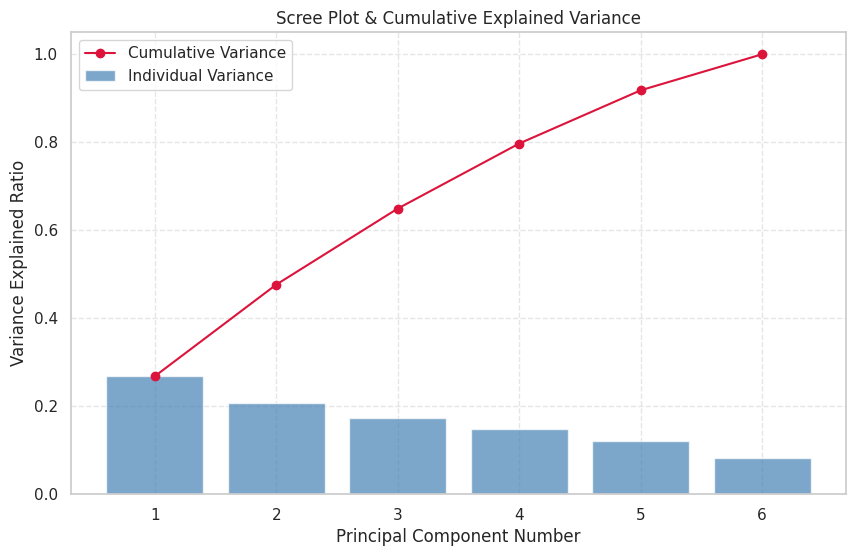

In [48]:
plt.figure(figsize=(10, 6)) # Set figure size for the scree plot
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7, color='steelblue', label='Individual Variance') # Plot bar chart for individual variance
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-', color='crimson', label='Cumulative Variance') # Plot line chart for cumulative variance
plt.title('Scree Plot & Cumulative Explained Variance') # Assign descriptive title to the plot
plt.xlabel('Principal Component Number') # Label the horizontal axis
plt.ylabel('Variance Explained Ratio') # Label the vertical axis
plt.xticks(range(1, len(explained_variance) + 1)) # Set ticks on horizontal axis to match component numbers
plt.legend(loc='best') # Add legend to the plot at the optimal location
plt.grid(True, linestyle='--', alpha=0.5) # Add background grid with thin dashed lines
plt.show() # Display the completed plot

### 6.7 PCA with Two Principal Components

In [49]:
pca_2d = PCA(n_components=2) # Initialize PCA restricted to exactly 2 principal components
pca_2d_transformed = pca_2d.fit_transform(pca_scaled) # Fit 2D PCA model and transform standardized data
pca_2d_df = pd.DataFrame(pca_2d_transformed, columns=['PC1', 'PC2']) # Wrap the 2D component scores into a DataFrame

display(pca_2d_df.head()) # Preview first 5 rows of the 2D principal component scores
print("2D PCA scores shape:", pca_2d_df.shape) # Print shape of the 2D PCA scores DataFrame

,PC1,PC2
0,-0.112514,4.622143
1,-1.396927,-0.604261
2,-0.678935,-0.460792
3,-1.326159,-0.627289
4,-0.356419,1.570527


2D PCA scores shape: (17137, 2)


### 6.8 PCA Visualization

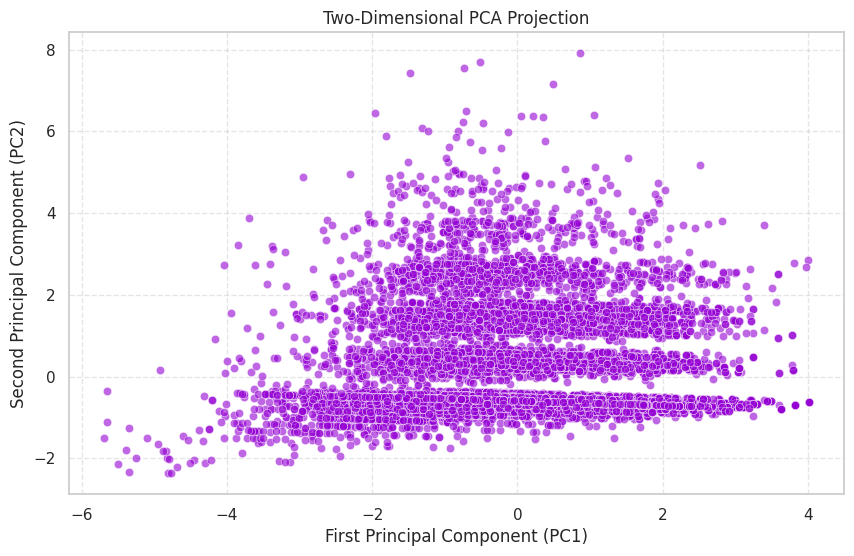

In [50]:
plt.figure(figsize=(10, 6)) # Define dimensions for the visualization canvas
sns.scatterplot(data=pca_2d_df, x='PC1', y='PC2', alpha=0.6, color='darkviolet') # Draw a scatter plot of observations along PC1 and PC2
plt.title('Two-Dimensional PCA Projection') # Set plot title
plt.xlabel('First Principal Component (PC1)') # Label horizontal coordinate axis
plt.ylabel('Second Principal Component (PC2)') # Label vertical coordinate axis
plt.grid(True, linestyle='--', alpha=0.5) # Overlay background guide grid
plt.show() # Render the 2D PCA scatter plot

### 6.9 Principal Component Loadings

,PC1,PC2,PC3,PC4,PC5,PC6
prestige,0.6475,-0.0407,0.0224,0.3112,-0.0119,-0.6940
educ,0.6612,-0.0277,0.0332,0.2161,-0.0212,0.7168
tvhours,-0.3782,-0.1625,0.1077,0.9025,-0.0159,0.0651
babies,-0.0129,0.4679,0.7160,-0.0147,-0.5175,-0.0141
preteen,-0.0017,0.7194,0.0246,0.1374,0.6804,0.0070
teens,-0.0197,0.4845,-0.6881,0.1514,-0.5180,0.0078


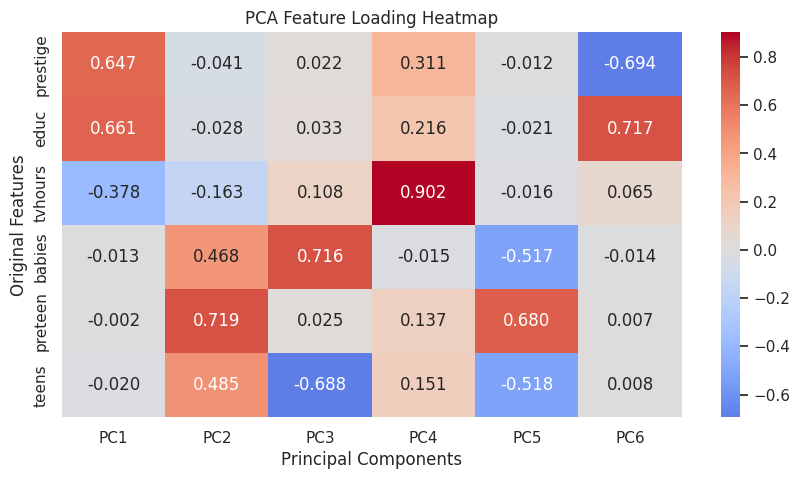

In [51]:
loadings_matrix = pca_obj.components_.T # Transpose PCA components matrix to map features as rows and components as columns
loadings_df = pd.DataFrame(loadings_matrix, index=pca_cols, columns=component_names) # Pack the loadings matrix into a DataFrame with labels

display(loadings_df.round(4)) # Display the rounded loadings DataFrame table
plt.figure(figsize=(10, 5)) # Set canvas size for the loadings heatmap
sns.heatmap(loadings_df, annot=True, cmap='coolwarm', center=0, fmt='.3f') # Display correlation loadings as an annotated heatmap
plt.title('PCA Feature Loading Heatmap') # Title the heatmap plot
plt.ylabel('Original Features') # Label the features axis
plt.xlabel('Principal Components') # Label the components axis
plt.show() # Display the loading heatmap visualization

## Module 7: Simple Linear Regression (SLR)

### 7.1 Import Required Libraries

In [52]:
from sklearn.linear_model import LinearRegression # Import the LinearRegression estimator class
from sklearn.model_selection import train_test_split # Import train_test_split to split variables into subsets
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score # Import standard regression performance metrics
import pandas as pd # Import pandas for data structuring and operations
import numpy as np # Import numpy for array and mathematical utility operations
import matplotlib.pyplot as plt # Import matplotlib pyplot for charts rendering
import seaborn as sns # Import seaborn library for plotting statistical regression fits

### 7.2 Data Preparation

In [53]:
slr_data = df[['educ', 'prestige']].copy() # Select educ as predictor and prestige as target and duplicate
slr_data = slr_data.dropna() # Drop any observations containing missing values to guarantee clean data input
slr_X = slr_data[['educ']] # Define the independent variable X as a 2D array structure
slr_y = slr_data['prestige'] # Define the dependent target variable y as a 1D vector series

display(slr_data.head()) # Display first 5 rows of the prepared regression dataset
print("Prepared SLR dataset shape:", slr_data.shape) # Print row and column dimensions of the clean regression data

,educ,prestige
0,12.0,46.0
1,12.0,22.0
2,12.0,29.0
3,8.0,42.0
4,13.0,36.0


Prepared SLR dataset shape: (17137, 2)


### 7.3 Visualizing the Relationship

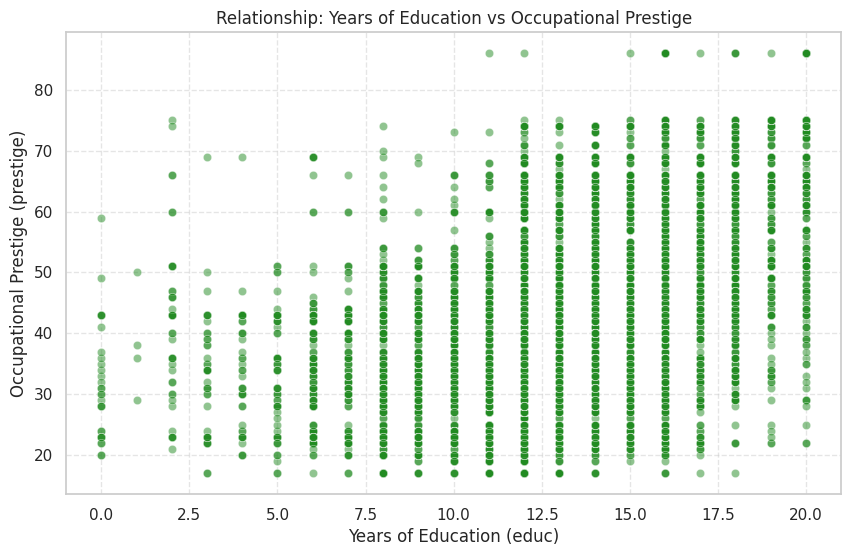

In [54]:
plt.figure(figsize=(10, 6)) # Initialize size of regression plot canvas
sns.scatterplot(data=slr_data, x='educ', y='prestige', alpha=0.5, color='forestgreen') # Generate scatter plot correlating education and prestige
plt.title('Relationship: Years of Education vs Occupational Prestige') # Title the relationship plot
plt.xlabel('Years of Education (educ)') # Set horizontal label description
plt.ylabel('Occupational Prestige (prestige)') # Set vertical label description
plt.grid(True, linestyle='--', alpha=0.5) # Apply guide grids on layout
plt.show() # Display the scatter relationship

### 7.4 Splitting Training and Testing Data

In [55]:
slr_X_train, slr_X_test, slr_y_train, slr_y_test = train_test_split(slr_X, slr_y, test_size=0.20, random_state=42) # Split dataset into 80% training and 20% testing subsets
print("Training Set Predictor Shape:", slr_X_train.shape) # Output size of training independent features
print("Testing Set Predictor Shape:", slr_X_test.shape) # Output size of testing independent features
print("Training Set Target Shape:", slr_y_train.shape) # Output size of training dependent outcomes
print("Testing Set Target Shape:", slr_y_test.shape) # Output size of testing dependent outcomes

Training Set Predictor Shape: (13709, 1)
Testing Set Predictor Shape: (3428, 1)
Training Set Target Shape: (13709,)
Testing Set Target Shape: (3428,)


### 7.5 Training the Linear Regression Model

In [56]:
slr_model = LinearRegression() # Instantiate the ordinary least squares linear regression estimator
slr_model.fit(slr_X_train, slr_y_train) # Fit and train the regression model on the training data matrices

LinearRegression()

### 7.6 Model Coefficient and Intercept

In [57]:
slope = slr_model.coef_[0] # Extract the model's estimated weight coefficient for education
intercept = slr_model.intercept_ # Extract the model's y-axis intercept coefficient

print("Model Slope (Coefficient):", round(slope, 4)) # Display the rounded model slope
print("Model Intercept:", round(intercept, 4)) # Display the rounded model intercept
print(f"Regression Equation: prestige = {intercept:.4f} + {slope:.4f} * educ") # Print the finalized linear relationship formula

Model Slope (Coefficient): 2.3126
Model Intercept: 13.0364
Regression Equation: prestige = 13.0364 + 2.3126 * educ


### 7.7 Making Predictions

In [58]:
slr_y_pred = slr_model.predict(slr_X_test) # Predict prestige scores using the test subset predictors
prediction_errors = slr_y_test - slr_y_pred # Calculate differences between observed outcomes and predicted scores
comparison_df = pd.DataFrame({ # Assemble a comparison table for predictions
    'Actual Prestige': slr_y_test, # Insert column for actual target values
    'Predicted Prestige': slr_y_pred, # Insert column for predicted values
    'Error (Residual)': prediction_errors # Insert column for computed errors
}) # End DataFrame compilation

display(comparison_df.head(10).round(4)) # Display the first 10 rows of the rounded comparison lookup table

,Actual Prestige,Predicted Prestige,Error (Residual)
7359,32.0,50.0387,-18.0387
6695,30.0,40.7881,-10.7881
13759,74.0,40.7881,33.2119
290,34.0,45.4134,-11.4134
2820,46.0,47.7260,-1.7260
10804,29.0,40.7881,-11.7881
6515,28.0,40.7881,-12.7881
11785,44.0,45.4134,-1.4134
16445,40.0,31.5375,8.4625
16811,31.0,45.4134,-14.4134


### 7.8 Model Evaluation

In [59]:
slr_mae = mean_absolute_error(slr_y_test, slr_y_pred) # Calculate average magnitude of errors
slr_mse = mean_squared_error(slr_y_test, slr_y_pred) # Calculate average of squared errors
slr_rmse = np.sqrt(slr_mse) # Compute square root of the mean squared error
slr_r2 = r2_score(slr_y_test, slr_y_pred) # Retrieve coefficient of determination metric

print("Mean Absolute Error (MAE):", round(slr_mae, 4)) # Display rounded MAE metric
print("Mean Squared Error (MSE):", round(slr_mse, 4)) # Display rounded MSE metric
print("Root Mean Squared Error (RMSE):", round(slr_rmse, 4)) # Display rounded RMSE metric
print("R-squared (R2 Score):", round(slr_r2, 4)) # Display rounded R2 score metric

Mean Absolute Error (MAE): 9.3687
Mean Squared Error (MSE): 136.3658
Root Mean Squared Error (RMSE): 11.6776
R-squared (R2 Score): 0.2462


### 7.9 Regression Line Visualization

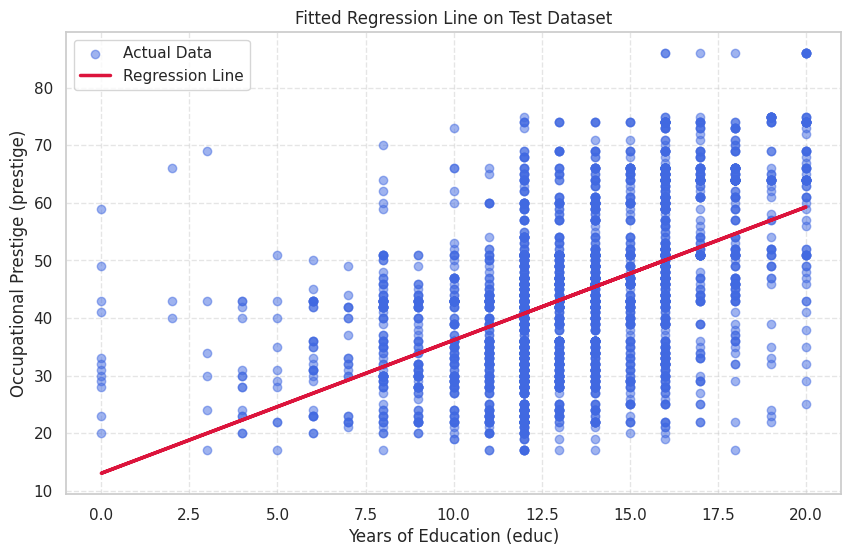

In [60]:
plt.figure(figsize=(10, 6)) # Setup coordinate canvas constraints
plt.scatter(slr_X_test, slr_y_test, color='royalblue', alpha=0.5, label='Actual Data') # Draw scatter plot of actual testing observations
plt.plot(slr_X_test, slr_y_pred, color='crimson', linewidth=2.5, label='Regression Line') # Overlay the fitted linear regression line
plt.title('Fitted Regression Line on Test Dataset') # Set visualization title
plt.xlabel('Years of Education (educ)') # Add horizontal label
plt.ylabel('Occupational Prestige (prestige)') # Add vertical label
plt.legend() # Position map legend markers on chart
plt.grid(True, linestyle='--', alpha=0.5) # Apply visual guide grid lines
plt.show() # Display the scatter regression line plot

### 7.10 Actual vs Predicted Values

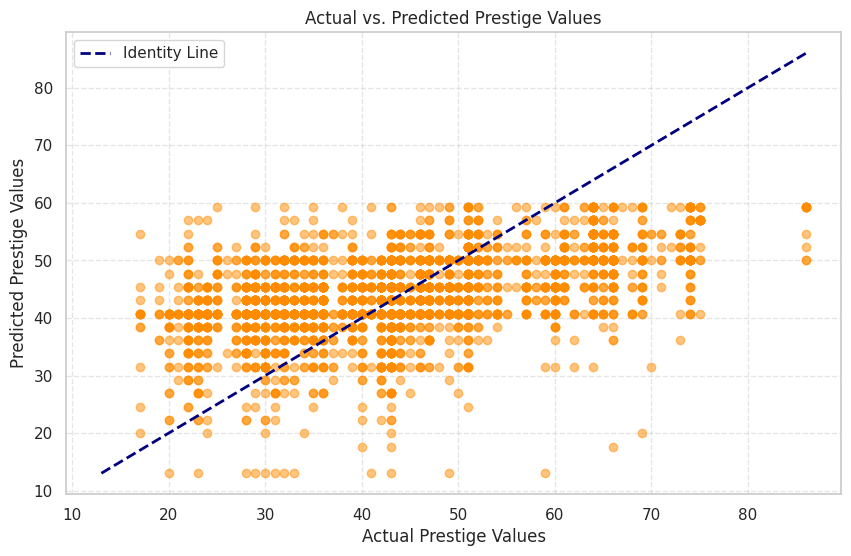

In [61]:
plt.figure(figsize=(10, 6)) # Instantiate coordinates framework bounds
plt.scatter(slr_y_test, slr_y_pred, color='darkorange', alpha=0.5) # Scatter plot test actuals against prediction outputs
min_val = min(slr_y_test.min(), slr_y_pred.min()) # Locate lower limit threshold metric
max_val = max(slr_y_test.max(), slr_y_pred.max()) # Locate upper limit threshold metric
plt.plot([min_val, max_val], [min_val, max_val], color='navy', linestyle='--', linewidth=2, label='Identity Line') # Draw 45-degree diagonal reference line
plt.title('Actual vs. Predicted Prestige Values') # Title plot display
plt.xlabel('Actual Prestige Values') # Assign horizontal axis description
plt.ylabel('Predicted Prestige Values') # Assign vertical axis description
plt.legend() # Position map legend markers on chart
plt.grid(True, linestyle='--', alpha=0.5) # Add grid line indicators
plt.show() # Display actual vs. predicted plot

### 7.11 Residual Analysis

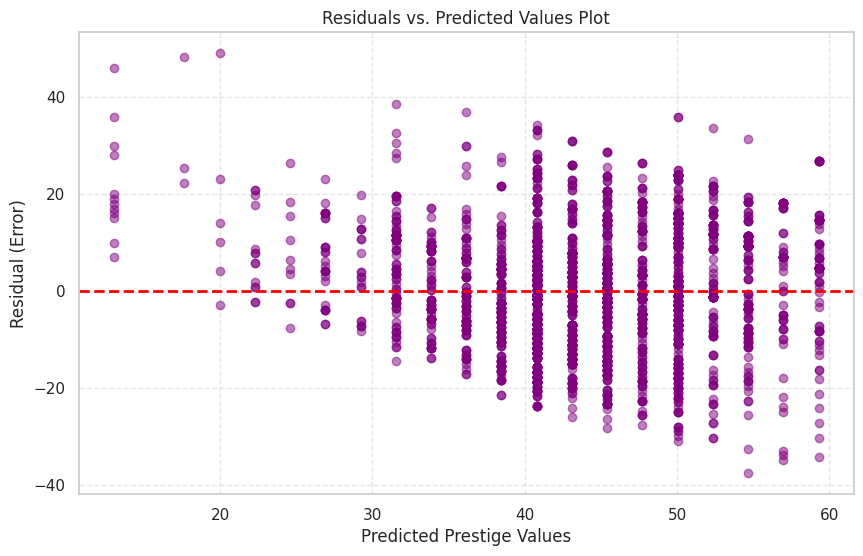

In [62]:
plt.figure(figsize=(10, 6)) # Define canvas space for residual analysis chart
plt.scatter(slr_y_pred, prediction_errors, color='purple', alpha=0.5) # Plot prediction values against residuals
plt.axhline(y=0, color='red', linestyle='--', linewidth=2) # Draw horizontal reference line at zero
plt.title('Residuals vs. Predicted Values Plot') # Title diagnostic chart
plt.xlabel('Predicted Prestige Values') # Assign horizontal axis description
plt.ylabel('Residual (Error)') # Assign vertical axis description
plt.grid(True, linestyle='--', alpha=0.5) # Apply guide grids on layout
plt.show() # Display residuals vs. predicted values plot

### 7.12 Distribution of Residuals

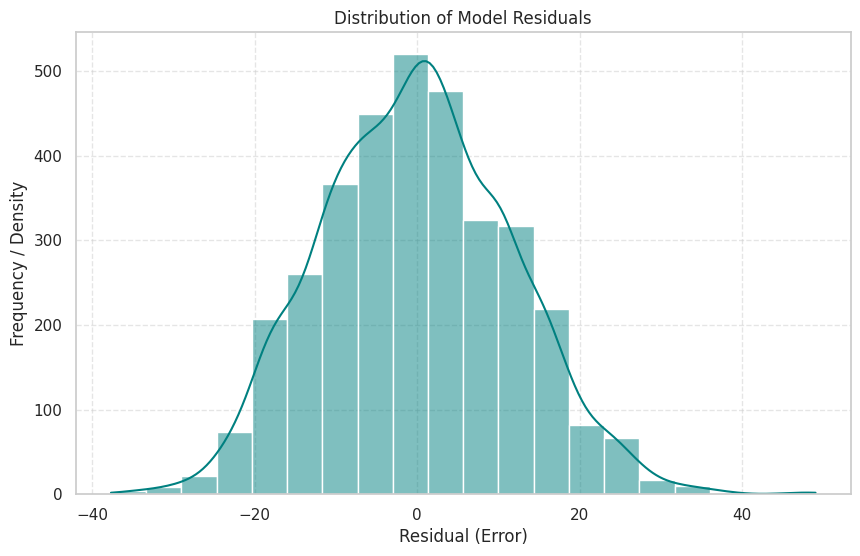

In [63]:
plt.figure(figsize=(10, 6)) # Set canvas size for residuals distribution
sns.histplot(prediction_errors, kde=True, color='teal', bins=20) # Draw histogram plot of errors with kernel density overlay
plt.title('Distribution of Model Residuals') # Title error distribution plot
plt.xlabel('Residual (Error)') # Assign horizontal axis description
plt.ylabel('Frequency / Density') # Assign vertical axis description
plt.grid(True, linestyle='--', alpha=0.5) # Add background grid guide markings
plt.show() # Render error distribution histogram